<a href="https://colab.research.google.com/github/Jeffrey-Huber/Predicting-Wildfire-Occurrence-Across-California/blob/main/wildfire_nn_feature_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# California Wildfire Occurrence: NN Feature Matrix

This notebook builds the **cell-year feature matrix** for the neural network. It uses the same grid, label and predictors as the baseline logistic regression in `STAT585_Project_2`. It doesn't make any plots, do exploratory analysis or write files.

**One row = one ~5 km grid cell in one year.**

| | Source | Variables |
|---|---|---|
| Label `fire` | USFS Fire Occurrence Points (Drive) | 1 if at least one ignition in the cell that year |
| Climate (6) | gridMET via `pygridmet` | fire-season (May–Oct) extremes of rolling windows |
| Vegetation (5) | RAP cover API | annual, herbaceous, shrub, tree, litter cover (%) |
| Region (1) | California Seed Zones (Drive) | categorical `Seed_Zone` |

**Outputs (in memory):**
- `full_data`: one row per cell-year with raw features and the label
- `X_train / X_val / X_test`, `y_*`, `meta_*`: scaled, one-hot, `float32` arrays for a tabular network (MLP)
- `X_grid`, `y_grid`, `mask_grid`, `zone_grid`: the same features as `(year, channel, H, W)` maps for a CNN (optional section)

In [ ]:
!pip install -q pygridmet

In [ ]:
!pip install -q h5netcdf

In [ ]:
import time
from pathlib import Path
import warnings
import concurrent.futures

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import requests
import pygridmet as gridmet
from shapely.geometry import box

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings('ignore', category=DeprecationWarning)

Mounted at /content/drive


## 1. Configuration

In [ ]:
# ---- Paths ----
# Colab can only see a "Shared with me" folder after it has a shortcut in My Drive:
# in Drive, right-click 585_project2 > Organize > Add shortcut > My Drive.
MY_DRIVE = Path('/content/drive/MyDrive')
CANDIDATE_DIRS = [
    MY_DRIVE / 'stat585' / '585_project2',   # original layout
    MY_DRIVE / '585_project2',               # shortcut in My Drive root
]
DATA_DIR = next((d for d in CANDIDATE_DIRS if d.exists()), None)
if DATA_DIR is None:  # look up to two folders deep for the shortcut
    found = list(MY_DRIVE.glob('*/585_project2')) + list(MY_DRIVE.glob('*/*/585_project2'))
    if not found:
        raise FileNotFoundError(
            "585_project2 isn't visible in My Drive. In Google Drive, right-click the "
            "shared folder > Organize > Add shortcut > My Drive, then rerun this cell."
        )
    DATA_DIR = found[0]

FIRE_CSV = DATA_DIR / 'National_USFS_Fire_Occurrence_Point_(Feature_Layer).csv'
# The seed-zone file may or may not carry a .geojson extension in Drive
SEED_ZONES_PATH = next(DATA_DIR.glob('California_Seed_Zones*'))
print(f"Data folder: {DATA_DIR}")
print(f"Seed zones:  {SEED_ZONES_PATH.name}")

CA_BOUNDARY_URL = (
    'https://raw.githubusercontent.com/johan/world.geo.json/'
    'master/countries/USA/CA.geo.json'
)
RAP_URL = 'https://us-central1-rap-data-365417.cloudfunctions.net/coverV3'

# ---- Study design ----
YEARS = range(2000, 2026)                 # 2000-2025 inclusive
GRID_SIZE = 0.05                          # degrees (~5 km)
FIRE_SEASON_MONTHS = [5, 6, 7, 8, 9, 10]  # May-Oct

# Time-based split. The test years match the logistic baseline (2022-2025);
# 2019-2021 is held out of training for validation / early stopping.
TRAIN_YEARS = range(2000, 2019)
VAL_YEARS   = range(2019, 2022)
TEST_YEARS  = range(2022, 2026)

# ---- Features (same as the logistic regression) ----
# feature name: (gridMET var, rolling window in days, rolling stat, season stat)
CLIMATE_SPECS = {
    'tmmx_previous_7_day_mean_c': ('tmmx', 7,  'mean', 'max'),  # hottest week
    'tmmn_previous_7_day_mean_c': ('tmmn', 7,  'mean', 'max'),  # warmest-night week
    'rain_previous_90_days_mm':   ('pr',   90, 'sum',  'min'),  # driest 90 days
    'wind_previous_3_day_max':    ('vs',   3,  'max',  'max'),  # windiest spell
    'rmin_previous_7_day_mean':   ('rmin', 7,  'mean', 'min'),  # driest-air week
    'srad_previous_7_day_mean':   ('srad', 7,  'mean', 'max'),  # sunniest week
}
CLIMATE_FEATURES = list(CLIMATE_SPECS)
GRIDMET_VARS = sorted({spec[0] for spec in CLIMATE_SPECS.values()})

# bare_ground is left out: the six RAP covers sum to ~100%, so it is redundant.
RAP_RENAME = {
    'AFG': 'ann_forb_grass',
    'PFG': 'peren_forb_grass',
    'SHR': 'shrub',
    'TRE': 'tree',
    'LTR': 'litter',
}
RAP_FEATURES = list(RAP_RENAME.values())

NUMERIC_FEATURES = CLIMATE_FEATURES + RAP_FEATURES
CATEGORICAL_FEATURES = ['Seed_Zone']
MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

## 2. California grid

In [ ]:
california_boundary = gpd.read_file(CA_BOUNDARY_URL).to_crs('EPSG:4326')
ca_geom = california_boundary.geometry
ca_polygon = ca_geom.union_all() if hasattr(ca_geom, 'union_all') else ca_geom.unary_union

min_lon, min_lat, max_lon, max_lat = ca_polygon.bounds
lon_values = np.arange(np.floor(min_lon / GRID_SIZE) * GRID_SIZE, max_lon, GRID_SIZE)
lat_values = np.arange(np.floor(min_lat / GRID_SIZE) * GRID_SIZE, max_lat, GRID_SIZE)

grid_records = []
for lon in lon_values:
    for lat in lat_values:
        cell = box(lon, lat, lon + GRID_SIZE, lat + GRID_SIZE)
        if ca_polygon.contains(cell.centroid):  # keep cells whose center is in CA
            grid_records.append({
                'grid_lon': round(lon + GRID_SIZE / 2, 4),
                'grid_lat': round(lat + GRID_SIZE / 2, 4),
                'geometry': cell,
            })

california_grid = gpd.GeoDataFrame(grid_records, crs='EPSG:4326')
california_grid['cell_id'] = range(len(california_grid))

# Row/column position of each cell on a regular lattice (used for the CNN tensors)
california_grid['row'] = np.rint(
    (california_grid['grid_lat'].max() - california_grid['grid_lat']) / GRID_SIZE
).astype(int)
california_grid['col'] = np.rint(
    (california_grid['grid_lon'] - california_grid['grid_lon'].min()) / GRID_SIZE
).astype(int)

print(f"California cells: {len(california_grid):,}")

## 3. Fire labels (USFS Fire Occurrence Points)

In [ ]:
fires = pd.read_csv(FIRE_CSV, usecols=['discoverydatetime', 'latdd83', 'longdd83'])
fires = fires.dropna(subset=['latdd83', 'longdd83'])

fires['fire_date'] = (
    pd.to_datetime(fires['discoverydatetime'], errors='coerce', utc=True)
    .dt.tz_localize(None)
    .dt.normalize()
)
fires = fires[fires['fire_date'].dt.year.between(YEARS.start, YEARS.stop - 1)].copy()
fires['year'] = fires['fire_date'].dt.year.astype(int)

fire_points = gpd.GeoDataFrame(
    fires[['year']],
    geometry=gpd.points_from_xy(fires['longdd83'], fires['latdd83']),
    crs='EPSG:4326',
)

# Keep fires inside California, then assign each to a grid cell
fire_points = gpd.sjoin(fire_points, california_boundary[['geometry']], predicate='within')
fire_points = fire_points.drop(columns='index_right')
fire_points = gpd.sjoin(
    fire_points, california_grid[['cell_id', 'geometry']], how='inner', predicate='within'
)

fire_labels = fire_points[['cell_id', 'year']].drop_duplicates()
fire_labels['fire'] = 1

print(f"California fires 2000-2025: {len(fire_points):,}")
print(f"Cell-years with >=1 fire:   {len(fire_labels):,}")

California fires 2000-2025: 130,980
Cell-years with >=1 fire:   63,678


## 4. Seed zones

In [ ]:
seed_zones = gpd.read_file(SEED_ZONES_PATH).to_crs('EPSG:4326')

grid_centers = california_grid[['cell_id', 'geometry']].copy()
grid_centers['geometry'] = grid_centers.geometry.representative_point()

grid_seed_zones = (
    gpd.sjoin(grid_centers, seed_zones[['SEED_ZONE', 'geometry']], how='left', predicate='within')
    [['cell_id', 'SEED_ZONE']]
    .rename(columns={'SEED_ZONE': 'Seed_Zone'})
    .drop_duplicates('cell_id')   # guard against overlapping zone polygons
)

print(f"Cells without a seed zone: {grid_seed_zones['Seed_Zone'].isna().sum():,}")

Cells without a seed zone: 50


## 5. Vegetation cover (RAP)

This makes one request per grid cell, and the API returns every year for that point. Failed requests are retried. RAP uses negative values (−99) for masked pixels, so those are set to NaN.

In [ ]:
def fetch_rap_all_years(cell_id, lat, lon, retries=3):
    payload = {
        'type': 'Feature',
        'geometry': {'type': 'Point', 'coordinates': [lon, lat]},
        'properties': {'mask': True, 'year': None},
    }
    for attempt in range(retries):
        try:
            response = requests.post(RAP_URL, json=payload, timeout=30)
            if response.status_code == 200:
                raw = response.json()['properties']['cover']
                cover = pd.DataFrame(raw[1:], columns=raw[0]).apply(pd.to_numeric, errors='coerce')
                cover = cover[cover['year'].between(YEARS.start, YEARS.stop - 1)].copy()
                cover['year'] = cover['year'].astype(int)
                cover['cell_id'] = cell_id
                return cover.to_dict('records')
        except Exception:
            pass
        time.sleep(2 ** attempt)
    return []


rap_results, failed_cells = [], []
cells = list(california_grid[['cell_id', 'grid_lat', 'grid_lon']].itertuples(index=False))
print(f"Fetching RAP cover for {len(cells):,} cells...")

with concurrent.futures.ThreadPoolExecutor(max_workers=20) as executor:
    futures = {executor.submit(fetch_rap_all_years, c.cell_id, c.grid_lat, c.grid_lon): c.cell_id
               for c in cells}
    for i, future in enumerate(concurrent.futures.as_completed(futures), start=1):
        result = future.result()
        if result:
            rap_results.extend(result)
        else:
            failed_cells.append(futures[future])
        if i % 2000 == 0:
            print(f"  {i:,} / {len(futures):,}")

rap_cover = (
    pd.DataFrame(rap_results)
    .rename(columns=RAP_RENAME)
    [['cell_id', 'year'] + RAP_FEATURES]
    .drop_duplicates(['cell_id', 'year'])
)
rap_cover[RAP_FEATURES] = rap_cover[RAP_FEATURES].where(rap_cover[RAP_FEATURES] >= 0)

print(f"RAP rows: {len(rap_cover):,}   failed cells: {len(failed_cells):,}")

Fetching RAP cover for 16,657 cells...
  2,000 / 16,657
  4,000 / 16,657


KeyboardInterrupt: 

## 6. Climate features (gridMET via `pygridmet`)

For each year this downloads only a padded California bounding box, from 90 days before January 1 through October 31. That's enough history for the 90-day rain window on May 1. Each cell takes its nearest gridMET pixel. For every day of May–October, the notebook computes the rolling window over the *previous* days, then keeps the season's most fire-favorable value. This is the same definition as the project notebook.

`pygridmet` returns dimensions `time / lat / lon` with short variable names. Temperatures come back in Kelvin. Each year's request is about 1 GB in memory before it's reduced to the grid cells.

In [ ]:
# ---- gridMET: load the yearly CONUS files directly (same as the original notebook) ----
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

GRIDMET_URL = 'https://www.northwestknowledge.net/metdata/data'
DRIVE_GRIDMET_DIR = DATA_DIR / 'gridmet_data'        # shared folder: read-only, used if files exist
LOCAL_GRIDMET_DIR = Path('/content/gridmet_data')    # Colab temporary disk, cleaned as we go
LOCAL_GRIDMET_DIR.mkdir(exist_ok=True)

pad = 0.1
gx0, gy0, gx1, gy1 = california_grid.total_bounds
LON_MIN, LAT_MIN, LON_MAX, LAT_MAX = gx0 - pad, gy0 - pad, gx1 + pad, gy1 + pad

cell_ids = california_grid['cell_id'].to_numpy()
lat_xr = xr.DataArray(california_grid['grid_lat'].to_numpy(), dims='cell')
lon_xr = xr.DataArray(california_grid['grid_lon'].to_numpy(), dims='cell')


def gridmet_file(var, year, retries=3):
    """Path to {var}_{year}.nc: the shared Drive copy if present, otherwise download it."""
    name = f'{var}_{year}.nc'
    drive_path = DRIVE_GRIDMET_DIR / name
    if drive_path.exists():
        return drive_path

    local_path = LOCAL_GRIDMET_DIR / name
    if local_path.exists():
        return local_path

    part_path = LOCAL_GRIDMET_DIR / f'{name}.part'
    for attempt in range(retries):
        try:
            with requests.get(f'{GRIDMET_URL}/{name}', stream=True, timeout=300) as response:
                response.raise_for_status()
                with open(part_path, 'wb') as f:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        f.write(chunk)
                expected = response.headers.get('Content-Length')
            if expected is not None and part_path.stat().st_size != int(expected):
                raise IOError(f'incomplete download of {name}')
            part_path.rename(local_path)
            return local_path
        except Exception as err:
            print(f'  {name} attempt {attempt + 1} failed: {err}')
            part_path.unlink(missing_ok=True)
            time.sleep(15 * (attempt + 1))
    raise RuntimeError(f'Could not download {name}')


def load_ca_window(var, start, end):
    """Daily California subset of one gridMET variable between two dates (dims: day, lat, lon)."""
    pieces = []
    for file_year in range(start.year, end.year + 1):
        with xr.open_dataset(gridmet_file(var, file_year), engine='h5netcdf') as ds:
            name = next(v for v in ds.data_vars if v != 'crs')
            da = ds[name]
            lat_slice = (slice(LAT_MAX, LAT_MIN) if da.lat[0] > da.lat[-1]
                         else slice(LAT_MIN, LAT_MAX))
            pieces.append(
                da.sel(day=slice(max(start, pd.Timestamp(f'{file_year}-01-01')),
                                 min(end, pd.Timestamp(f'{file_year}-12-31'))),
                       lat=lat_slice, lon=slice(LON_MIN, LON_MAX)).load()
            )
    return xr.concat(pieces, dim='day').sortby('day')


def to_celsius(da):
    # Convert Kelvin to Celsius (no air temperature in C is above 100)
    return da - 273.15 if float(da.median()) > 100 else da


def season_summary(daily, window, roll_stat, season_stat):
    # Rolling window over the previous `window` days, then a fire-season extreme
    rolled = getattr(daily.rolling(day=window, min_periods=window), roll_stat)()
    rolled = rolled.shift(day=1)   # the window ends the day before
    season = rolled.sel(day=rolled['day'].dt.month.isin(FIRE_SEASON_MONTHS))
    return getattr(season, season_stat)(dim='day')


climate_rows = []
for year in YEARS:
    t0 = time.time()
    start = pd.Timestamp(f'{year}-01-01') - pd.Timedelta(days=90)   # history for the 90-day rain window
    end = pd.Timestamp(f'{year}-{max(FIRE_SEASON_MONTHS):02d}-01') + pd.offsets.MonthEnd(0)

    out = pd.DataFrame({'cell_id': cell_ids, 'year': year})
    missing = {}
    daily_by_var = {}
    for var in GRIDMET_VARS:
        window = load_ca_window(var, start, end)
        daily_by_var[var] = window.sel(lat=lat_xr, lon=lon_xr, method='nearest')
        missing[var] = float(daily_by_var[var].isnull().all('day').mean())
        del window

    for feature, (var, window_days, roll_stat, season_stat) in CLIMATE_SPECS.items():
        daily = daily_by_var[var]
        if var in ('tmmx', 'tmmn'):
            daily = to_celsius(daily)
        out[feature] = season_summary(daily, window_days, roll_stat, season_stat).values

    climate_rows.append(out)
    del daily_by_var

    # The previous year's downloaded files are no longer needed: free the disk space
    for var in GRIDMET_VARS:
        (LOCAL_GRIDMET_DIR / f'{var}_{year - 1}.nc').unlink(missing_ok=True)

    worst = max(missing, key=missing.get)
    print(f'{year} done ({time.time() - t0:.0f}s) | cells missing data: '
          f'max {missing[worst]:.1%} ({worst})')

climate_all = pd.concat(climate_rows, ignore_index=True)

## 7. Assemble the cell-year table

In [ ]:
grid_years = california_grid[['cell_id', 'grid_lat', 'grid_lon', 'row', 'col']].merge(
    pd.DataFrame({'year': list(YEARS)}), how='cross'
)

full_data = (
    grid_years
    .merge(fire_labels, on=['cell_id', 'year'], how='left')
    .merge(grid_seed_zones, on='cell_id', how='left')
    .merge(rap_cover, on=['cell_id', 'year'], how='left')
    .merge(climate_all, on=['cell_id', 'year'], how='left')
)
full_data['fire'] = full_data['fire'].fillna(0).astype(int)

assert len(full_data) == len(california_grid) * len(YEARS)
assert not full_data.duplicated(['cell_id', 'year']).any()

print(f"full_data: {full_data.shape}")
print("Missing values (%):")
print(full_data[MODEL_FEATURES].isna().mean().mul(100).round(2).sort_values(ascending=False))

## 8. Feature matrix for a tabular network

- Rows with any missing predictor are dropped, as in the baseline.
- Numeric features are standardized using **training-year statistics only**, so validation and test years don't leak into the scaling.
- `Seed_Zone` is fully one-hot encoded. A neural network doesn't need a dropped reference level. Zones not seen in training map to all zeros.
- `zone_idx_*` gives the same zone as an integer (0 = unseen), in case you want an embedding layer instead of one-hot columns.
- `meta_*` keeps `cell_id`, `year`, `grid_lat` and `grid_lon` aligned with each row so predictions can be mapped back.

In [ ]:
model_data = full_data.dropna(subset=MODEL_FEATURES).copy()
model_data['Seed_Zone'] = model_data['Seed_Zone'].astype(str)

split_of_year = {**{y: 'train' for y in TRAIN_YEARS},
                 **{y: 'val' for y in VAL_YEARS},
                 **{y: 'test' for y in TEST_YEARS}}
model_data['split'] = model_data['year'].map(split_of_year)
parts = {name: model_data[model_data['split'] == name] for name in ['train', 'val', 'test']}

preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), NUMERIC_FEATURES),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
])
preprocessor.fit(parts['train'][MODEL_FEATURES])
feature_names = list(preprocessor.get_feature_names_out())

zone_categories = sorted(parts['train']['Seed_Zone'].unique())
zone_to_idx = {z: i + 1 for i, z in enumerate(zone_categories)}   # 0 = unseen zone

META_COLS = ['cell_id', 'year', 'grid_lat', 'grid_lon']


def make_arrays(df):
    X = preprocessor.transform(df[MODEL_FEATURES]).astype(np.float32)
    y = df['fire'].to_numpy(dtype=np.float32)
    zone_idx = df['Seed_Zone'].map(zone_to_idx).fillna(0).to_numpy(dtype=np.int64)
    meta = df[META_COLS].reset_index(drop=True)
    return X, y, zone_idx, meta


X_train, y_train, zone_idx_train, meta_train = make_arrays(parts['train'])
X_val,   y_val,   zone_idx_val,   meta_val   = make_arrays(parts['val'])
X_test,  y_test,  zone_idx_test,  meta_test  = make_arrays(parts['test'])

# Weight for the positive class in a weighted BCE loss (negatives / positives)
pos_weight = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))

print(f"{len(feature_names)} input features "
      f"({len(NUMERIC_FEATURES)} numeric + {len(feature_names) - len(NUMERIC_FEATURES)} seed-zone columns)")
for name, X, y in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    print(f"{name:5s}  X {X.shape}   fire rate {y.mean():.3%}")
print(f"pos_weight = {pos_weight:.1f}")

## 9. MLP NN - NO `pos_weight`

In [ ]:
!pip install -q ISLP torchinfo

In [ ]:
import torch
from torch import nn
from torch.utils.data import TensorDataset
from torchinfo import summary
from torchmetrics.classification import BinaryAveragePrecision, BinaryAUROC

from pytorch_lightning import Trainer, seed_everything
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

from ISLP.torch import SimpleDataModule, SimpleModule, ErrorTracker, rec_num_workers
from sklearn.metrics import average_precision_score, roc_auc_score
from matplotlib.pyplot import subplots

seed_everything(0, workers=True)
torch.use_deterministic_algorithms(True, warn_only=True)
max_num_workers = rec_num_workers()

INFO:lightning_fabric.utilities.seed:Seed set to 0


### Data module
This uses your year-based train/val/test split instead of a random 20% hold-out.

In [ ]:
def to_dataset(X, y):
    return TensorDataset(torch.from_numpy(X), torch.from_numpy(y))

train_ds = to_dataset(X_train, y_train)
val_ds   = to_dataset(X_val, y_val)
test_ds  = to_dataset(X_test, y_test)

fire_dm = SimpleDataModule(train_ds,
                           test_ds,
                           validation=val_ds,      # 2019-2021, not a random split
                           num_workers=max_num_workers,
                           batch_size=1024)

for idx, (X_, Y_) in enumerate(fire_dm.train_dataloader()):
    print('X: ', X_.shape, X_.dtype)
    print('Y: ', Y_.shape, Y_.dtype)
    if idx >= 1:
        break

X:  torch.Size([1024, 102]) torch.float32
Y:  torch.Size([1024]) torch.float32
X:  torch.Size([1024, 102]) torch.float32
Y:  torch.Size([1024]) torch.float32


### Network

In [ ]:
class WildfireMLP(nn.Module):
    def __init__(self, n_inputs, hidden=(128, 64), dropout=0.3):
        super().__init__()
        layers = []
        prev = n_inputs
        for units in hidden:                      # each hidden layer: Linear -> ReLU -> Dropout
            layers += [nn.Linear(prev, units), nn.ReLU(), nn.Dropout(dropout)]
            prev = units
        layers.append(nn.Linear(prev, 1))         # one output: the log-odds of fire
        self._forward = nn.Sequential(*layers)

    def forward(self, x):
        return self._forward(x).squeeze(-1)       # shape (batch,) to match y

n_inputs = X_train.shape[1]
mlp_model = WildfireMLP(n_inputs)
print(mlp_model(X_).shape)
summary(mlp_model, input_data=X_, col_names=['input_size', 'output_size', 'num_params'])

torch.Size([1024])


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
WildfireMLP                              [1024, 102]               [1024]                    --
├─Sequential: 1-1                        [1024, 102]               [1024, 1]                 --
│    └─Linear: 2-1                       [1024, 102]               [1024, 128]               13,184
│    └─ReLU: 2-2                         [1024, 128]               [1024, 128]               --
│    └─Dropout: 2-3                      [1024, 128]               [1024, 128]               --
│    └─Linear: 2-4                       [1024, 128]               [1024, 64]                8,256
│    └─ReLU: 2-5                         [1024, 64]                [1024, 64]                --
│    └─Dropout: 2-6                      [1024, 64]                [1024, 64]                --
│    └─Linear: 2-7                       [1024, 64]                [1024, 1]                 65
Total params: 21,505
Trainab

In [ ]:
def make_module(model, lr=1e-3):
    return SimpleModule(
        model,
        loss=nn.BCEWithLogitsLoss(),  # up-weights the rare fires
        optimizer=torch.optim.Adam(model.parameters(), lr=lr),
        metrics={'average_precision': BinaryAveragePrecision(),
                 'auroc': BinaryAUROC()},
        pre_process_y_for_metrics=lambda y: y.int(),
    )


def fit_model(model, name, max_epochs=30, patience=5, lr=1e-3):
    module = make_module(model, lr=lr)
    logger = CSVLogger('logs', name=name)
    checkpoint = ModelCheckpoint(monitor='valid_average_precision', mode='max')
    trainer = Trainer(deterministic=True,
                      accelerator='cpu',
                      max_epochs=max_epochs,
                      logger=logger,
                      enable_progress_bar=False,
                      callbacks=[ErrorTracker(),
                                 EarlyStopping(monitor='valid_average_precision',
                                               mode='max', patience=patience),
                                 checkpoint])
    trainer.fit(module, datamodule=fire_dm)
    return trainer, module, logger, checkpoint


def load_best(model, checkpoint):
    state = torch.load(checkpoint.best_model_path, map_location='cpu', weights_only=False)['state_dict']
    model.load_state_dict({k.removeprefix('model.'): v
                           for k, v in state.items() if k.startswith('model.')})
    return model


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X))).numpy()

### MLP architecture

We use a fully connected feedforward network (a multilayer perceptron) with **two hidden layers**. Each row of input is one grid cell in one year. The output is the predicted probability that at least one fire starts in that cell that year.

| Layer | Operation | Output size | Parameters |
|---|---|---|---|
| Input | 17 numeric features (standardized) + one-hot `Seed_Zone` columns | N inputs | – |
| Hidden layer 1 | Linear → ReLU → Dropout (0.3) | 128 | 128 × (N + 1) |
| Hidden layer 2 | Linear → ReLU → Dropout (0.3) | 64 | 128 × 64 + 64 = 8,256 |
| Output | Linear → sigmoid | 1 | 64 + 1 = 65 |

**Total trainable parameters:** 128N + 8,449 = **N** (from `torchinfo.summary`).

**Inputs (N = 17 + number of seed zones):**
- 11 gridMET climate features, each the fire-season (May–Oct) extreme of a rolling window: max and min temperature, 90-day rainfall, wind, max and min humidity, solar radiation, VPD, ERC, and 100-hr and 1000-hr fuel moisture
- 6 RAP vegetation cover features: annual and perennial forbs/grasses, shrub, tree, litter, bare ground
- `Seed_Zone`, one-hot encoded (one column per zone)

Numeric features are standardized using the training years only.

**Training setup:**
- **Optimizer:** Adam, learning rate 0.001
- **Batch size:** 1,024
- **Epochs:** up to 30, with early stopping (patience 5) on validation PR-AUC; the weights from the best validation epoch are kept
- **Data split by year:** train 2000–2018, validation 2019–2021, test 2022–2025

**Evaluation:** average precision (PR-AUC) and ROC-AUC on the test years. Accuracy is misleading because only a few percent of cell-years have a fire. As a baseline, we trained the same network with no hidden layers, which is equivalent to logistic regression, using the same setup.

### Train MLP

In [ ]:
mlp_trainer, mlp_module, mlp_logger, mlp_ckpt = fit_model(mlp_model, 'Wildfire_MLP')

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ WildfireMLP       │ 21.5 K │ train │     0 │
│ 1 │ loss  │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴───────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 21.5 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.5 K                                                                                               
Total estimated model params size (MB): 0.086                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

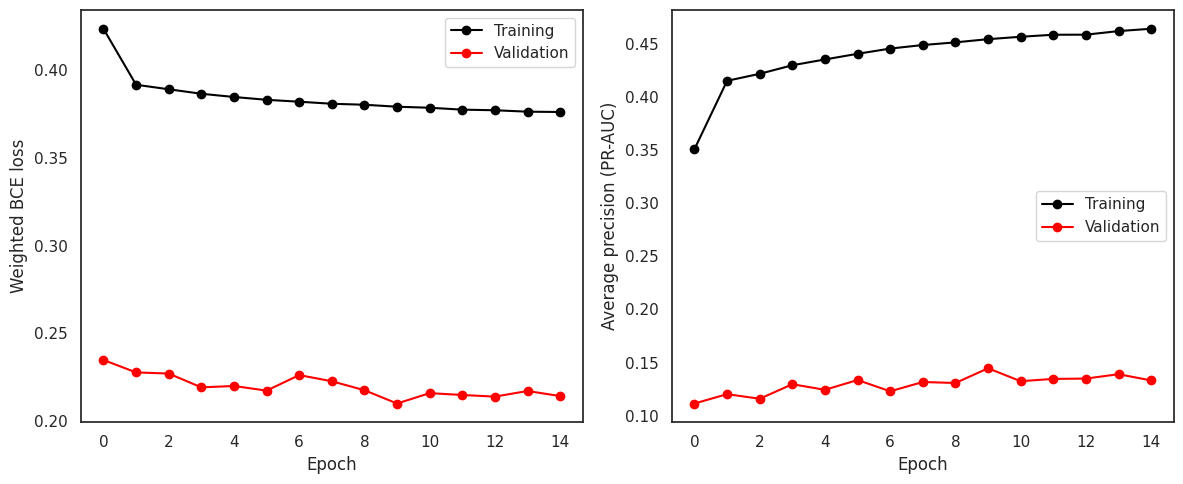

In [ ]:
def plot_history(logger, col, ylabel, ax):
    results = pd.read_csv(logger.experiment.metrics_file_path)
    train_col = f'train_{col}_epoch' if f'train_{col}_epoch' in results else f'train_{col}'
    for column, color, label in [(train_col, 'black', 'Training'),
                                 (f'valid_{col}', 'red', 'Validation')]:
        results.dropna(subset=[column]).plot(x='epoch', y=column, label=label,
                                             marker='o', color=color, ax=ax)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    return ax

fig, axes = subplots(1, 2, figsize=(12, 5))
plot_history(mlp_logger, 'loss', 'Weighted BCE loss', axes[0])
plot_history(mlp_logger, 'average_precision', 'Average precision (PR-AUC)', axes[1])
fig.tight_layout()

### Evaluate over 2022-2025

In [ ]:
mlp_model = load_best(mlp_model, mlp_ckpt)
mlp_test_prob = predict_proba(mlp_model, X_test)

print(f"Test PR-AUC (average precision): {average_precision_score(y_test, mlp_test_prob):.4f}")
print(f"Test ROC-AUC:                    {roc_auc_score(y_test, mlp_test_prob):.4f}")
print(f"No-skill PR-AUC (= fire rate):   {y_test.mean():.4f}")

Test PR-AUC (average precision): 0.1344
Test ROC-AUC:                    0.7943
No-skill PR-AUC (= fire rate):   0.0457


###  viz

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, precision_recall_curve,
                             roc_curve, f1_score)

# Pick the decision threshold on the VALIDATION years (best F1), then apply it to test.
# (pos_weight inflates the predicted probabilities, so 0.5 isn't meaningful here.)
mlp_val_prob = predict_proba(mlp_model, X_val)
candidate_thresholds = np.linspace(0.01, 0.95, 95)
val_f1 = [f1_score(y_val.astype(int), (mlp_val_prob >= t).astype(int)) for t in candidate_thresholds]
THRESHOLD = float(candidate_thresholds[int(np.argmax(val_f1))])
print(f"Threshold chosen on validation years: {THRESHOLD:.2f}")

mlp_test_pred = (mlp_test_prob >= THRESHOLD).astype(int)
print(classification_report(y_test.astype(int), mlp_test_pred, zero_division=0))

Threshold chosen on validation years: 0.22
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     38597
           1       0.12      0.58      0.20      1849

    accuracy                           0.79     40446
   macro avg       0.55      0.69      0.54     40446
weighted avg       0.94      0.79      0.85     40446



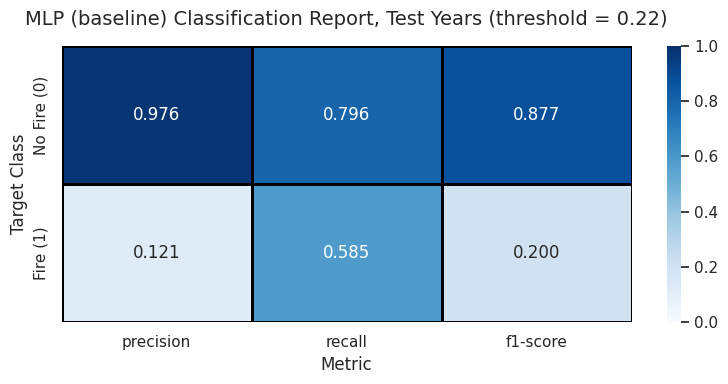

In [ ]:
report_dict = classification_report(y_test.astype(int), mlp_test_pred, zero_division=0, output_dict=True)
report_df = pd.DataFrame(
    {metric: [report_dict[cls][metric] for cls in ['0', '1']]
     for metric in ['precision', 'recall', 'f1-score']},
    index=['No Fire (0)', 'Fire (1)'],
)

plt.figure(figsize=(8, 4))
sns.set_theme(style='white')
sns.heatmap(report_df, annot=True, cmap='Blues', fmt='.3f', cbar=True,
            linewidths=1, linecolor='black', vmin=0, vmax=1)
plt.title(f'MLP (baseline) Classification Report, Test Years (threshold = {THRESHOLD:.2f})', fontsize=14, pad=15)
plt.xlabel('Metric', fontsize=12)
plt.ylabel('Target Class', fontsize=12)
plt.tight_layout()
plt.show()

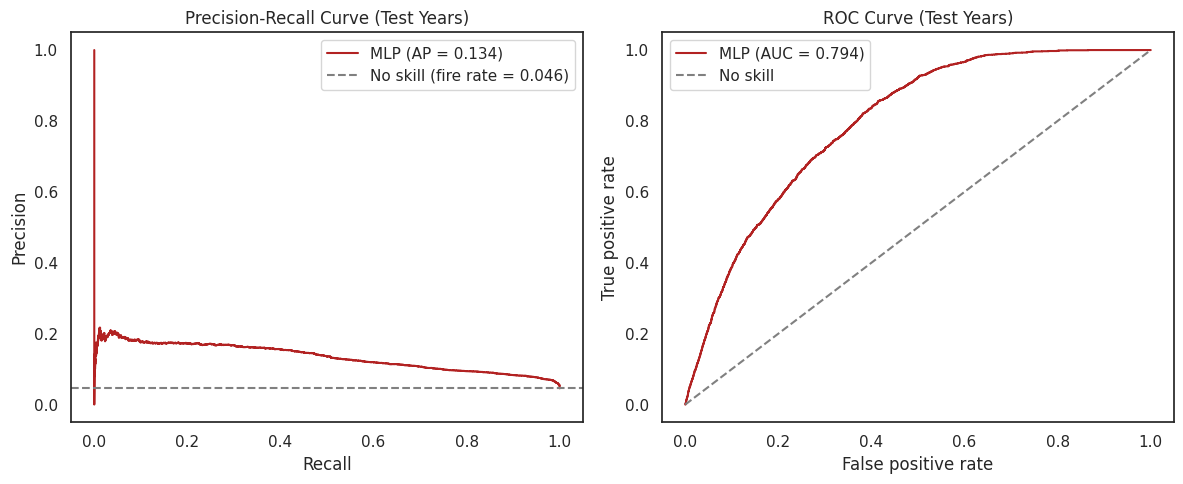

In [ ]:
precision, recall, _ = precision_recall_curve(y_test, mlp_test_prob)
fpr, tpr, _ = roc_curve(y_test, mlp_test_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.set_theme(style='whitegrid')

axes[0].plot(recall, precision, color='firebrick',
             label=f'MLP (AP = {average_precision_score(y_test, mlp_test_prob):.3f})')
axes[0].axhline(y_test.mean(), color='grey', linestyle='--',
                label=f'No skill (fire rate = {y_test.mean():.3f})')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall Curve (Test Years)')
axes[0].legend()

axes[1].plot(fpr, tpr, color='firebrick',
             label=f'MLP (AUC = {roc_auc_score(y_test, mlp_test_prob):.3f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--', label='No skill')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC Curve (Test Years)')
axes[1].legend()

plt.tight_layout()
plt.show()

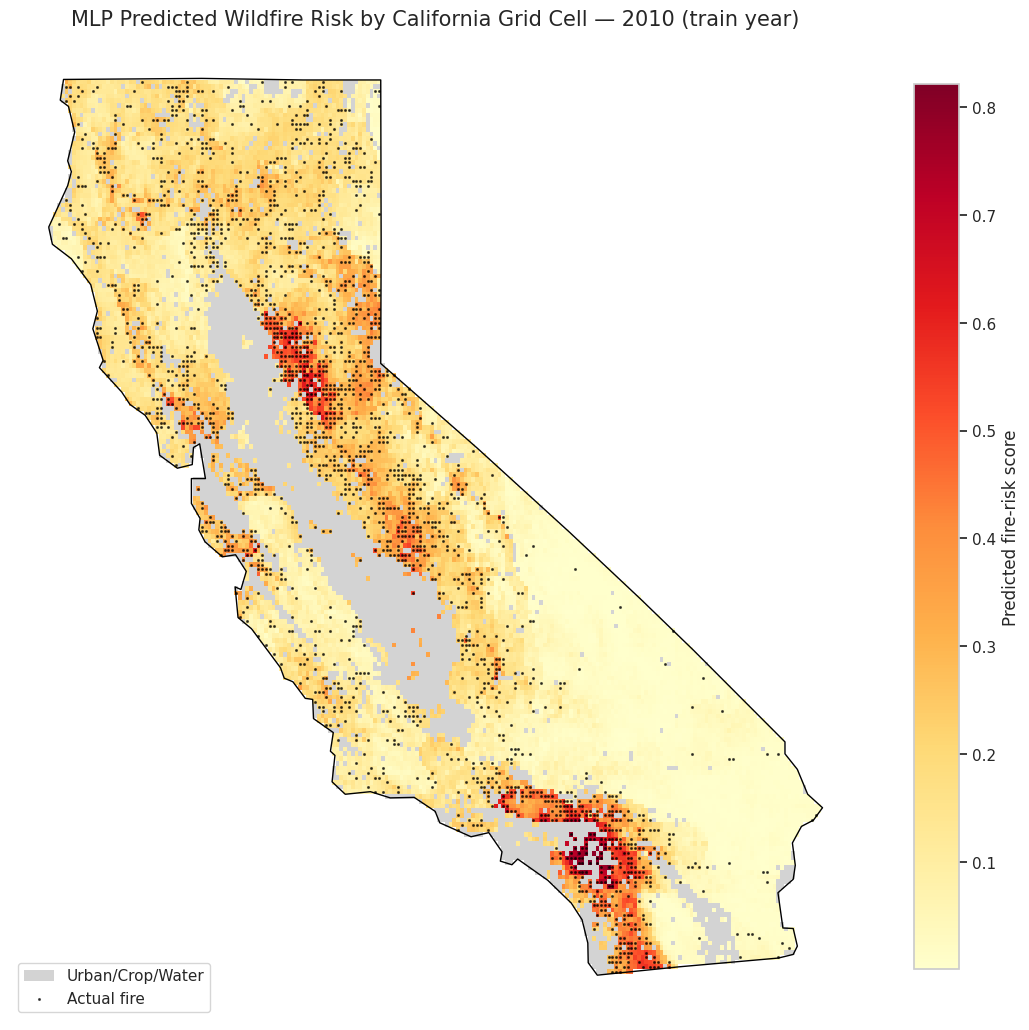

In [ ]:
# Predicted risk for every cell-year (train, validation and test years)
X_all = preprocessor.transform(model_data[MODEL_FEATURES]).astype(np.float32)
all_predictions = model_data[['cell_id', 'year', 'split', 'fire']].copy()
all_predictions['risk_score'] = predict_proba(mlp_model, X_all)

MAP_YEAR = 2010
SHOW_ACTUAL_FIRES = True   # overlay the cells that actually had a fire that year

map_data = all_predictions.loc[all_predictions['year'] == MAP_YEAR,
                               ['cell_id', 'risk_score', 'fire']]
risk_cells = california_grid[['cell_id', 'geometry']].merge(map_data, on='cell_id', how='left')

year_split = split_of_year.get(MAP_YEAR, 'unused')   # train / val / test

fig, ax = plt.subplots(figsize=(11, 13))
risk_cells.plot(
    ax=ax,
    column='risk_score',
    cmap='YlOrRd',
    vmin=risk_cells['risk_score'].min(),
    vmax=risk_cells['risk_score'].max(),
    edgecolor='none',
    legend=True,
    legend_kwds={'label': 'Predicted fire-risk score', 'shrink': 0.7},
    missing_kwds={'color': 'lightgrey', 'label': 'Urban/Crop/Water'},
)
if SHOW_ACTUAL_FIRES:
    fire_cells = risk_cells[risk_cells['fire'] == 1]
    fire_cells.geometry.representative_point().plot(ax=ax, color='black', markersize=1.5,
                                                    alpha=0.6, label='Actual fire')
    ax.legend(loc='lower left')

california_boundary.to_crs('EPSG:4326').boundary.plot(ax=ax, color='black', linewidth=1)
ax.set_title(f'MLP (baseline) Predicted Wildfire Risk by California Grid Cell — {MAP_YEAR} '
             f'({year_split} year)', fontsize=15)
ax.set_axis_off()
plt.tight_layout()
plt.show()

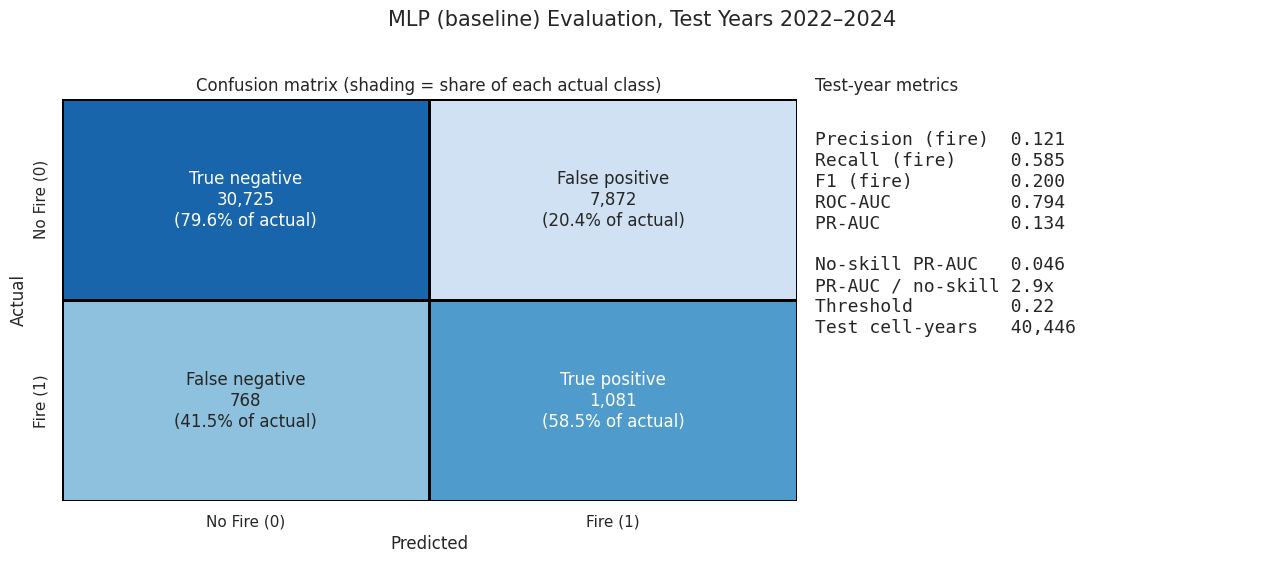

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

y_true = y_test.astype(int)
cm = confusion_matrix(y_true, mlp_test_pred, labels=[0, 1])
cm_row_pct = cm / cm.sum(axis=1, keepdims=True)      # share of each actual class

cell_names = np.array([['True negative', 'False positive'],
                       ['False negative', 'True positive']])
annot = np.array([[f"{cell_names[i, j]}\n{cm[i, j]:,}\n({cm_row_pct[i, j]:.1%} of actual)"
                   for j in range(2)] for i in range(2)])

metrics = {
    'Precision (fire)': precision_score(y_true, mlp_test_pred, zero_division=0),
    'Recall (fire)':    recall_score(y_true, mlp_test_pred, zero_division=0),
    'F1 (fire)':        f1_score(y_true, mlp_test_pred, zero_division=0),
    'ROC-AUC':          roc_auc_score(y_test, mlp_test_prob),
    'PR-AUC':           average_precision_score(y_test, mlp_test_prob),
}

fig, (ax_cm, ax_txt) = plt.subplots(1, 2, figsize=(13, 5.5),
                                    gridspec_kw={'width_ratios': [1.6, 1]})
sns.set_theme(style='white')
sns.heatmap(cm_row_pct, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
            linewidths=1, linecolor='black', annot_kws={'fontsize': 12}, ax=ax_cm,
            xticklabels=['No Fire (0)', 'Fire (1)'], yticklabels=['No Fire (0)', 'Fire (1)'])
ax_cm.set_xlabel('Predicted', fontsize=12)
ax_cm.set_ylabel('Actual', fontsize=12)
ax_cm.set_title('Confusion matrix (shading = share of each actual class)', fontsize=12)

ax_txt.axis('off')
lines = [f"{name:<18}{value:.3f}" for name, value in metrics.items()]
lines += ['',
          f"{'No-skill PR-AUC':<18}{y_test.mean():.3f}",
          f"{'PR-AUC / no-skill':<18}{metrics['PR-AUC'] / y_test.mean():.1f}x",
          f"{'Threshold':<18}{THRESHOLD:.2f}",
          f"{'Test cell-years':<18}{len(y_true):,}"]
ax_txt.text(0.0, 0.92, '\n'.join(lines), va='top', family='monospace', fontsize=13)
ax_txt.set_title('Test-year metrics', fontsize=12, loc='left')

fig.suptitle(f'MLP (baseline) Evaluation, Test Years {min(TEST_YEARS)}–{max(TEST_YEARS)}',
             fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# Extra Scratch Code

## missing values

In [ ]:
missing_by_year = (
    full_data
    .assign(any_missing=full_data[MODEL_FEATURES].isna().any(axis=1))
    .groupby('year')
    .agg(cells_missing=('any_missing', 'sum'),
         pct_missing=('any_missing', 'mean'))
)
missing_by_year['pct_missing'] = (missing_by_year['pct_missing'] * 100).round(2)

print(missing_by_year.sort_values('pct_missing'))
print("\nFewest missing:", missing_by_year['pct_missing'].idxmin())

In [ ]:
full_data.groupby('year')[MODEL_FEATURES].apply(lambda d: d.isna().mean().mul(100).round(2))

## Sudden decrease of reported fires after 2015

Issue: There is a sudden decrease in fire rate for years after 2015

In [ ]:
# 1. True training PR-AUC, measured the same way as validation (dropout off, full set)
train_prob = predict_proba(mlp_model, X_train)
val_prob = predict_proba(mlp_model, X_val)
print(f"Train PR-AUC (eval mode): {average_precision_score(y_train, train_prob):.3f}")
print(f"Val   PR-AUC:             {average_precision_score(y_val, val_prob):.3f}")

# 2. Compare with each split's no-skill level (its fire rate)
for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(f"{name:5s} fire rate: {y.mean():.3%}")

# 3. Fire rate by year: look for a step change around 2015-2016
print(full_data.groupby('year')['fire'].mean().mul(100).round(2))

Scenario:

In [ ]:
check = pd.read_csv(FIRE_CSV, usecols=['discoverydatetime', 'latdd83', 'longdd83',
                                       'owneragency', 'protectionagency',
                                       'datasource', 'pointtype', 'dbsourceid'],
                    low_memory=False)
check['year'] = pd.to_datetime(check['discoverydatetime'], errors='coerce', utc=True).dt.year
check = check[check['year'].between(2010, 2021)]

# Keep California fires only
pts = gpd.GeoDataFrame(check, geometry=gpd.points_from_xy(check.longdd83, check.latdd83), crs='EPSG:4326')
ca = gpd.sjoin(pts, california_boundary[['geometry']], predicate='within')

for col in ['owneragency', 'protectionagency', 'datasource', 'pointtype']:
    print(f"\n=== {col} (California fire counts by year) ===")
    print(pd.crosstab(ca[col].fillna('missing'), ca['year']))

### Why the fire rate drops after 2015

The share of grid cells with a fire falls from about 21% (2000–2015) to about 4–6% (2016 onward). To find out why, we broke down California fires by year using four columns from the USFS dataset: `owneragency`, `protectionagency`, `datasource`, and `pointtype`.

**Almost the whole drop is fires on private land.**

| Landowner at the ignition point | 2010–2015 (per year) | 2016–2021 (per year) |
|---|---|---|
| Private | ~4,200–6,900 | ~100–260 |
| USFS (National Forest) | ~840–1,430 | ~750–1,530 |
| All others (BIA, BLM, NPS, county, etc.) | a few hundred | a few dozen |

Fires on National Forest land stay steady across the break. What disappears in 2016 are thousands of fires on private land.

**The pre-2016 records come from a different, older source.** Nearly all California records before 2016:
- have `pointtype = Unknown`, meaning no record of how the location was determined,
- have no `protectionagency`,
-

### What this changes in the project

The question becomes narrower. The model now predicts fire starts on National Forest land. Most cells outside national forests will be 0 in every year, so the map mostly separates forest from non-forest areas. For sharper results, you could limit the grid to cells that overlap National Forest land.

# MLP tuning

## 1. reconfigure variables

In [ ]:
!pip install -q ISLP torchinfo h5netcdf

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import time
import warnings
import concurrent.futures
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import requests
from shapely.geometry import box

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Config

In [ ]:
# ---- Paths ----
# Colab can only see a "Shared with me" folder after it has a shortcut in My Drive:
# in Drive, right-click 585_project2 > Organize > Add shortcut > My Drive.
MY_DRIVE = Path('/content/drive/MyDrive')
CANDIDATE_DIRS = [
    MY_DRIVE / 'stat585' / '585_project2',   # original layout
    MY_DRIVE / '585_project2',               # shortcut in My Drive root
]
DATA_DIR = next((d for d in CANDIDATE_DIRS if d.exists()), None)
if DATA_DIR is None:  # look up to two folders deep for the shortcut
    found = list(MY_DRIVE.glob('*/585_project2')) + list(MY_DRIVE.glob('*/*/585_project2'))
    if not found:
        raise FileNotFoundError(
            "585_project2 isn't visible in My Drive. In Google Drive, right-click the "
            "shared folder > Organize > Add shortcut > My Drive, then rerun this cell."
        )
    DATA_DIR = found[0]

FIRE_CSV = DATA_DIR / 'National_USFS_Fire_Occurrence_Point_(Feature_Layer).csv'
SEED_ZONES_PATH = next(DATA_DIR.glob('California_Seed_Zones*'))   # extension may be missing in Drive
CA_BOUNDARY_URL = (
    'https://raw.githubusercontent.com/johan/world.geo.json/'
    'master/countries/USA/CA.geo.json'
)
RAP_URL = 'https://us-central1-rap-data-365417.cloudfunctions.net/coverV3'

GRIDMET_URL = 'https://www.northwestknowledge.net/metdata/data'
DRIVE_GRIDMET_DIR = DATA_DIR / 'gridmet_data'        # shared folder: read-only, used if files exist
LOCAL_GRIDMET_DIR = Path('/content/gridmet_data')    # Colab temporary disk, cleaned as we go
LOCAL_GRIDMET_DIR.mkdir(exist_ok=True)

print(f"Data folder: {DATA_DIR}")
print(f"Seed zones:  {SEED_ZONES_PATH.name}")

# ---- Study design ----
YEARS = range(2000, 2025)                 # 2000-2024 (2025 is nearly empty in the USFS file)
GRID_SIZE = 0.05                          # degrees (~5 km)
FIRE_SEASON_MONTHS = [5, 6, 7, 8, 9, 10]  # May-Oct

TRAIN_YEARS = range(2000, 2019)           # 2000-2018
VAL_YEARS   = range(2019, 2022)           # 2019-2021: early stopping and model choice
TEST_YEARS  = range(2022, 2025)           # 2022-2024: look at once, at the end
OWNER_FILTER = None

# ---- Climate features (10 gridMET variables) ----
# feature name: (gridMET var, rolling window in days, rolling stat, season stat)
# Each is the most fire-favorable value of that rolling window during May-Oct.
CLIMATE_SPECS = {
    'tmmx_previous_7_day_mean_c': ('tmmx',   7,  'mean', 'max'),  # hottest week
    'tmmn_previous_7_day_mean_c': ('tmmn',   7,  'mean', 'max'),  # warmest-night week
    'rain_previous_90_days_mm':   ('pr',     90, 'sum',  'min'),  # driest 90 days
    'wind_previous_3_day_max':    ('vs',     3,  'max',  'max'),  # windiest spell
    'rmax_previous_7_day_mean':   ('rmax',   7,  'mean', 'min'),  # lowest-humidity-peak week
    'rmin_previous_7_day_mean':   ('rmin',   7,  'mean', 'min'),  # driest-air week
    'srad_previous_7_day_mean':   ('srad',   7,  'mean', 'max'),  # sunniest week
    'vpd_previous_7_day_mean':    ('vpd',    7,  'mean', 'max'),  # thirstiest-air week
    'erc_previous_7_day_mean':    ('erc',    7,  'mean', 'max'),  # highest fire-energy week
    'fm1000_previous_7_day_mean': ('fm1000', 7,  'mean', 'min'),  # driest heavy fuels week
}
CLIMATE_FEATURES = list(CLIMATE_SPECS)
GRIDMET_VARS = sorted({spec[0] for spec in CLIMATE_SPECS.values()})

# ---- Vegetation features (all 6 RAP cover types) ----
RAP_RENAME = {
    'AFG': 'ann_forb_grass',
    'PFG': 'peren_forb_grass',
    'SHR': 'shrub',
    'TRE': 'tree',
    'LTR': 'litter',
    'BGR': 'bare_ground',
}
RAP_FEATURES = list(RAP_RENAME.values())

NUMERIC_FEATURES = CLIMATE_FEATURES + RAP_FEATURES
CATEGORICAL_FEATURES = ['Seed_Zone']
MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print(f"{len(CLIMATE_FEATURES)} climate + {len(RAP_FEATURES)} RAP features + Seed_Zone")

Data folder: /content/drive/MyDrive/585_project2
Seed zones:  California_Seed_Zones.geojson
10 climate + 6 RAP features + Seed_Zone


## 2. california grid

In [ ]:
california_boundary = gpd.read_file(CA_BOUNDARY_URL).to_crs('EPSG:4326')
ca_geom = california_boundary.geometry
ca_polygon = ca_geom.union_all() if hasattr(ca_geom, 'union_all') else ca_geom.unary_union

min_lon, min_lat, max_lon, max_lat = ca_polygon.bounds
lon_values = np.arange(np.floor(min_lon / GRID_SIZE) * GRID_SIZE, max_lon, GRID_SIZE)
lat_values = np.arange(np.floor(min_lat / GRID_SIZE) * GRID_SIZE, max_lat, GRID_SIZE)

grid_records = []
for lon in lon_values:
    for lat in lat_values:
        cell = box(lon, lat, lon + GRID_SIZE, lat + GRID_SIZE)
        if ca_polygon.contains(cell.centroid):  # keep cells whose center is in CA
            grid_records.append({
                'grid_lon': round(lon + GRID_SIZE / 2, 4),
                'grid_lat': round(lat + GRID_SIZE / 2, 4),
                'geometry': cell,
            })

california_grid = gpd.GeoDataFrame(grid_records, crs='EPSG:4326')
california_grid['cell_id'] = range(len(california_grid))

print(f"California cells: {len(california_grid):,}")

California cells: 16,657


## 3. Fire Labels


In [ ]:
fires = pd.read_csv(FIRE_CSV,
                    usecols=['discoverydatetime', 'latdd83', 'longdd83', 'owneragency'],
                    low_memory=False)
fires = fires.dropna(subset=['latdd83', 'longdd83'])

fires['fire_date'] = (
    pd.to_datetime(fires['discoverydatetime'], errors='coerce', utc=True)
    .dt.tz_localize(None)
    .dt.normalize()
)
fires = fires.dropna(subset=['fire_date'])
fires = fires[fires['fire_date'].dt.year.between(YEARS.start, YEARS.stop - 1)].copy()
fires['year'] = fires['fire_date'].dt.year.astype(int)
fires['owneragency'] = fires['owneragency'].astype(str).str.strip()

print("Owner labels, 2000-2009 (all states):")
print(fires.loc[fires['year'] < 2010, 'owneragency'].value_counts().head(10).to_string())

if OWNER_FILTER is not None:
    fires = fires[fires['owneragency'].isin(OWNER_FILTER)]

fire_points = gpd.GeoDataFrame(
    fires[['year']],
    geometry=gpd.points_from_xy(fires['longdd83'], fires['latdd83']),
    crs='EPSG:4326',
)

# Keep fires inside California, then assign each to a grid cell
fire_points = gpd.sjoin(fire_points, california_boundary[['geometry']], predicate='within')
fire_points = fire_points.drop(columns='index_right')
fire_points = gpd.sjoin(
    fire_points, california_grid[['cell_id', 'geometry']], how='inner', predicate='within'
)

fire_labels = fire_points[['cell_id', 'year']].drop_duplicates()
fire_labels['fire'] = 1

print(f"\nCalifornia fires kept: {len(fire_points):,}   cell-years with a fire: {len(fire_labels):,}")
print("Fires per year:")
print(fire_points.groupby('year').size().to_string())

Owner labels, 2000-2009 (all states):
owneragency
USFS       62875
Private    55458
nan         3129
BIA         2879
BLM         2535
OthLoc      2384
State       1833
NPS         1445
County       903
City         581

California fires kept: 130,954   cell-years with a fire: 63,655
Fires per year:
year
2000     7023
2001     8167
2002     7136
2003     7947
2004     7387
2005     6638
2006     8237
2007    10002
2008     7666
2009     6876
2010     5747
2011     8482
2012     7173
2013     8653
2014     6450
2015     7296
2016      956
2017     1660
2018      993
2019      993
2020     1540
2021     1097
2022      963
2023     1025
2024      847


## 4. seed zones

In [ ]:
seed_zones = gpd.read_file(SEED_ZONES_PATH).to_crs('EPSG:4326')

grid_centers = california_grid[['cell_id', 'geometry']].copy()
grid_centers['geometry'] = grid_centers.geometry.representative_point()

grid_seed_zones = (
    gpd.sjoin(grid_centers, seed_zones[['SEED_ZONE', 'geometry']], how='left', predicate='within')
    [['cell_id', 'SEED_ZONE']]
    .rename(columns={'SEED_ZONE': 'Seed_Zone'})
    .drop_duplicates('cell_id')   # guard against overlapping zone polygons
)

print(f"Cells without a seed zone: {grid_seed_zones['Seed_Zone'].isna().sum():,}")

Cells without a seed zone: 50


## 5. Vegetation Cover (RAP)

In [ ]:
def fetch_rap_all_years(cell_id, lat, lon, retries=3):
    payload = {
        'type': 'Feature',
        'geometry': {'type': 'Point', 'coordinates': [lon, lat]},
        'properties': {'mask': True, 'year': None},
    }
    for attempt in range(retries):
        try:
            response = requests.post(RAP_URL, json=payload, timeout=30)
            if response.status_code == 200:
                raw = response.json()['properties']['cover']
                cover = pd.DataFrame(raw[1:], columns=raw[0]).apply(pd.to_numeric, errors='coerce')
                cover = cover[cover['year'].between(YEARS.start, YEARS.stop - 1)].copy()
                cover['year'] = cover['year'].astype(int)
                cover['cell_id'] = cell_id
                return cover.to_dict('records')
        except Exception:
            pass
        time.sleep(2 ** attempt)
    return []


rap_results, failed_cells = [], []
cells = list(california_grid[['cell_id', 'grid_lat', 'grid_lon']].itertuples(index=False))
print(f"Fetching RAP cover for {len(cells):,} cells...")

with concurrent.futures.ThreadPoolExecutor(max_workers=20) as executor:
    futures = {executor.submit(fetch_rap_all_years, c.cell_id, c.grid_lat, c.grid_lon): c.cell_id
               for c in cells}
    for i, future in enumerate(concurrent.futures.as_completed(futures), start=1):
        result = future.result()
        if result:
            rap_results.extend(result)
        else:
            failed_cells.append(futures[future])
        if i % 2000 == 0:
            print(f"  {i:,} / {len(futures):,}")

rap_cover = (
    pd.DataFrame(rap_results)
    .rename(columns=RAP_RENAME)
    [['cell_id', 'year'] + RAP_FEATURES]
    .drop_duplicates(['cell_id', 'year'])
)
rap_cover[RAP_FEATURES] = rap_cover[RAP_FEATURES].where(rap_cover[RAP_FEATURES] >= 0)

print(f"RAP rows: {len(rap_cover):,}   failed cells: {len(failed_cells):,}")

Fetching RAP cover for 16,657 cells...
  2,000 / 16,657
  4,000 / 16,657
  6,000 / 16,657
  8,000 / 16,657
  10,000 / 16,657
  12,000 / 16,657
  14,000 / 16,657
  16,000 / 16,657
RAP rows: 416,425   failed cells: 0


## GridMET features

In [ ]:
pad = 0.1
gx0, gy0, gx1, gy1 = california_grid.total_bounds
LON_MIN, LAT_MIN, LON_MAX, LAT_MAX = gx0 - pad, gy0 - pad, gx1 + pad, gy1 + pad

cell_ids = california_grid['cell_id'].to_numpy()
lat_xr = xr.DataArray(california_grid['grid_lat'].to_numpy(), dims='cell')
lon_xr = xr.DataArray(california_grid['grid_lon'].to_numpy(), dims='cell')


def gridmet_file(var, year, retries=3):
    """Path to {var}_{year}.nc: the shared Drive copy if present, otherwise download it."""
    name = f'{var}_{year}.nc'
    drive_path = DRIVE_GRIDMET_DIR / name
    if drive_path.exists():
        return drive_path

    local_path = LOCAL_GRIDMET_DIR / name
    if local_path.exists():
        return local_path

    part_path = LOCAL_GRIDMET_DIR / f'{name}.part'
    for attempt in range(retries):
        try:
            with requests.get(f'{GRIDMET_URL}/{name}', stream=True, timeout=300) as response:
                response.raise_for_status()
                with open(part_path, 'wb') as f:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        f.write(chunk)
                expected = response.headers.get('Content-Length')
            if expected is not None and part_path.stat().st_size != int(expected):
                raise IOError(f'incomplete download of {name}')
            part_path.rename(local_path)
            return local_path
        except Exception as err:
            print(f'  {name} attempt {attempt + 1} failed: {err}')
            part_path.unlink(missing_ok=True)
            time.sleep(15 * (attempt + 1))
    raise RuntimeError(f'Could not download {name}')


def load_ca_window(var, start, end):
    """Daily California subset of one gridMET variable between two dates (dims: day, lat, lon)."""
    pieces = []
    for file_year in range(start.year, end.year + 1):
        with xr.open_dataset(gridmet_file(var, file_year), engine='h5netcdf') as ds:
            name = next(v for v in ds.data_vars if v != 'crs')
            da = ds[name]
            lat_slice = (slice(LAT_MAX, LAT_MIN) if da.lat[0] > da.lat[-1]
                         else slice(LAT_MIN, LAT_MAX))
            pieces.append(
                da.sel(day=slice(max(start, pd.Timestamp(f'{file_year}-01-01')),
                                 min(end, pd.Timestamp(f'{file_year}-12-31'))),
                       lat=lat_slice, lon=slice(LON_MIN, LON_MAX)).load()
            )
    return xr.concat(pieces, dim='day').sortby('day')


def to_celsius(da):
    # Convert Kelvin to Celsius (no air temperature in C is above 100)
    return da - 273.15 if float(da.median()) > 100 else da


def season_summary(daily, window, roll_stat, season_stat):
    # Rolling window over the previous `window` days, then a fire-season extreme
    rolled = getattr(daily.rolling(day=window, min_periods=window), roll_stat)()
    rolled = rolled.shift(day=1)   # the window ends the day before
    season = rolled.sel(day=rolled['day'].dt.month.isin(FIRE_SEASON_MONTHS))
    return getattr(season, season_stat)(dim='day')


climate_rows = []
for year in YEARS:
    t0 = time.time()
    start = pd.Timestamp(f'{year}-01-01') - pd.Timedelta(days=90)
    end = pd.Timestamp(f'{year}-{max(FIRE_SEASON_MONTHS):02d}-01') + pd.offsets.MonthEnd(0)

    out = pd.DataFrame({'cell_id': cell_ids, 'year': year})
    missing, daily_by_var = {}, {}
    for var in GRIDMET_VARS:
        window = load_ca_window(var, start, end)
        daily_by_var[var] = window.sel(lat=lat_xr, lon=lon_xr, method='nearest')
        missing[var] = float(daily_by_var[var].isnull().all('day').mean())
        del window

    for feature, (var, window_days, roll_stat, season_stat) in CLIMATE_SPECS.items():
        daily = daily_by_var[var]
        if var in ('tmmx', 'tmmn'):
            daily = to_celsius(daily)
        out[feature] = season_summary(daily, window_days, roll_stat, season_stat).values

    climate_rows.append(out)
    del daily_by_var

    # The previous year's downloaded files are no longer needed: free the disk space
    for var in GRIDMET_VARS:
        (LOCAL_GRIDMET_DIR / f'{var}_{year - 1}.nc').unlink(missing_ok=True)

    worst = max(missing, key=missing.get)
    print(f'{year} done ({time.time() - t0:.0f}s) | cells missing data: '
          f'max {missing[worst]:.1%} ({worst})')

climate_all = pd.concat(climate_rows, ignore_index=True)

2000 done (109s) | cells missing data: max 0.0% (erc)
2001 done (67s) | cells missing data: max 0.0% (erc)
2002 done (114s) | cells missing data: max 0.0% (erc)
2003 done (79s) | cells missing data: max 0.0% (erc)
2004 done (78s) | cells missing data: max 0.0% (erc)
2005 done (77s) | cells missing data: max 0.0% (erc)
2006 done (64s) | cells missing data: max 0.0% (erc)
2007 done (82s) | cells missing data: max 0.0% (erc)
2008 done (67s) | cells missing data: max 0.0% (erc)
2009 done (64s) | cells missing data: max 0.0% (erc)
2010 done (96s) | cells missing data: max 0.0% (erc)
2011 done (60s) | cells missing data: max 0.0% (erc)
2012 done (75s) | cells missing data: max 0.0% (erc)
2013 done (78s) | cells missing data: max 0.0% (erc)
2014 done (67s) | cells missing data: max 0.0% (erc)
2015 done (78s) | cells missing data: max 0.0% (erc)
2016 done (77s) | cells missing data: max 0.0% (erc)
2017 done (77s) | cells missing data: max 0.0% (erc)
2018 done (62s) | cells missing data: max 0.

## 7. Assemble table

In [ ]:
grid_years = california_grid[['cell_id', 'grid_lat', 'grid_lon']].merge(
    pd.DataFrame({'year': list(YEARS)}), how='cross'
)

full_data = (
    grid_years
    .merge(fire_labels, on=['cell_id', 'year'], how='left')
    .merge(grid_seed_zones, on='cell_id', how='left')
    .merge(rap_cover, on=['cell_id', 'year'], how='left')
    .merge(climate_all, on=['cell_id', 'year'], how='left')
)
full_data['fire'] = full_data['fire'].fillna(0).astype(int)

assert len(full_data) == len(california_grid) * len(YEARS)
assert not full_data.duplicated(['cell_id', 'year']).any()

print(f"full_data: {full_data.shape}")
print("\nMissing values (%):")
print(full_data[MODEL_FEATURES].isna().mean().mul(100).round(2).sort_values(ascending=False).to_string())
print("\nShare of cells with a fire, by year (%):")
print(full_data.groupby('year')['fire'].mean().mul(100).round(2).to_string())

full_data: (416425, 22)

Missing values (%):
tree                          19.04
peren_forb_grass              19.04
shrub                         19.04
litter                        19.04
bare_ground                   19.04
ann_forb_grass                19.04
Seed_Zone                      0.30
tmmx_previous_7_day_mean_c     0.00
tmmn_previous_7_day_mean_c     0.00
erc_previous_7_day_mean        0.00
vpd_previous_7_day_mean        0.00
srad_previous_7_day_mean       0.00
rmin_previous_7_day_mean       0.00
rmax_previous_7_day_mean       0.00
wind_previous_3_day_max        0.00
rain_previous_90_days_mm       0.00
fm1000_previous_7_day_mean     0.00

Share of cells with a fire, by year (%):
year
2000    20.63
2001    23.35
2002    20.65
2003    24.41
2004    21.93
2005    19.64
2006    23.18
2007    22.44
2008    20.94
2009    19.63
2010    17.18
2011    21.59
2012    20.49
2013    23.86
2014    19.43
2015    21.48
2016     4.05
2017     6.32
2018     4.10
2019     4.21
2020     5.94
20

## 8. feature matrix and class weighting

In [ ]:
model_data = full_data.dropna(subset=MODEL_FEATURES).copy()
model_data['Seed_Zone'] = model_data['Seed_Zone'].astype(str)

split_of_year = {**{y: 'train' for y in TRAIN_YEARS},
                 **{y: 'val' for y in VAL_YEARS},
                 **{y: 'test' for y in TEST_YEARS}}
model_data['split'] = model_data['year'].map(split_of_year)
parts = {name: model_data[model_data['split'] == name] for name in ['train', 'val', 'test']}

preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), NUMERIC_FEATURES),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
])
preprocessor.fit(parts['train'][MODEL_FEATURES])
feature_names = list(preprocessor.get_feature_names_out())

META_COLS = ['cell_id', 'year', 'grid_lat', 'grid_lon']


def make_arrays(df):
    X = preprocessor.transform(df[MODEL_FEATURES]).astype(np.float32)
    y = df['fire'].to_numpy(dtype=np.float32)
    meta = df[META_COLS].reset_index(drop=True)
    return X, y, meta


X_train, y_train, meta_train = make_arrays(parts['train'])
X_val,   y_val,   meta_val   = make_arrays(parts['val'])
X_test,  y_test,  meta_test  = make_arrays(parts['test'])

pos_weight = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))

print(f"{len(feature_names)} input features "
      f"({len(NUMERIC_FEATURES)} numeric + {len(feature_names) - len(NUMERIC_FEATURES)} seed-zone columns)")
for name, X, y in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    print(f"{name:5s}  X {X.shape}   fire rate {y.mean():.3%}")
print(f"pos_weight = {pos_weight:.1f}")

102 input features (16 numeric + 86 seed-zone columns)
train  X (256158, 102)   fire rate 17.697%
val    X (40446, 102)   fire rate 5.650%
test   X (40446, 102)   fire rate 4.572%
pos_weight = 4.7


## NN setup

In [ ]:
import torch
from torch import nn
from torch.utils.data import TensorDataset
from torchinfo import summary
from torchmetrics.classification import BinaryAveragePrecision, BinaryAUROC

from pytorch_lightning import Trainer, seed_everything
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

from ISLP.torch import SimpleDataModule, SimpleModule, ErrorTracker, rec_num_workers
from sklearn.metrics import (average_precision_score, roc_auc_score, classification_report,
                             precision_recall_curve, roc_curve, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns

seed_everything(0, workers=True)
torch.use_deterministic_algorithms(True, warn_only=True)
max_num_workers = rec_num_workers()

INFO:lightning_fabric.utilities.seed:Seed set to 0


In [ ]:
def to_dataset(X, y):
    return TensorDataset(torch.from_numpy(X), torch.from_numpy(y))

train_ds = to_dataset(X_train, y_train)
val_ds   = to_dataset(X_val, y_val)
test_ds  = to_dataset(X_test, y_test)

fire_dm = SimpleDataModule(train_ds,
                           test_ds,
                           validation=val_ds,      # 2019-2021, not a random split
                           num_workers=max_num_workers,
                           batch_size=1024)

for idx, (X_, Y_) in enumerate(fire_dm.train_dataloader()):
    print('X: ', X_.shape, X_.dtype)
    print('Y: ', Y_.shape, Y_.dtype)
    if idx >= 1:
        break

X:  torch.Size([1024, 102]) torch.float32
Y:  torch.Size([1024]) torch.float32
X:  torch.Size([1024, 102]) torch.float32
Y:  torch.Size([1024]) torch.float32


**Architecture:** input → 128 units → 64 units → 1 output, with ReLU and 30% dropout after each hidden layer.

In [ ]:
class WildfireMLP(nn.Module):
    def __init__(self, n_inputs, hidden=(128, 64), dropout=0.3):
        super().__init__()
        layers = []
        prev = n_inputs
        for units in hidden:                      # each hidden layer: Linear -> ReLU -> Dropout
            layers += [nn.Linear(prev, units), nn.ReLU(), nn.Dropout(dropout)]
            prev = units
        layers.append(nn.Linear(prev, 1))         # one output: the log-odds of fire
        self._forward = nn.Sequential(*layers)

    def forward(self, x):
        return self._forward(x).squeeze(-1)       # shape (batch,) to match y

n_inputs = X_train.shape[1]
mlp_model = WildfireMLP(n_inputs)
print(mlp_model(X_).shape)
summary(mlp_model, input_data=X_, col_names=['input_size', 'output_size', 'num_params'])

torch.Size([1024])


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
WildfireMLP                              [1024, 102]               [1024]                    --
├─Sequential: 1-1                        [1024, 102]               [1024, 1]                 --
│    └─Linear: 2-1                       [1024, 102]               [1024, 128]               13,184
│    └─ReLU: 2-2                         [1024, 128]               [1024, 128]               --
│    └─Dropout: 2-3                      [1024, 128]               [1024, 128]               --
│    └─Linear: 2-4                       [1024, 128]               [1024, 64]                8,256
│    └─ReLU: 2-5                         [1024, 64]                [1024, 64]                --
│    └─Dropout: 2-6                      [1024, 64]                [1024, 64]                --
│    └─Linear: 2-7                       [1024, 64]                [1024, 1]                 65
Total params: 21,505
Trainab

In [ ]:
def make_module(model, lr=1e-3):
    return SimpleModule(
        model,
        loss=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight)),  # class weighting
        optimizer=torch.optim.Adam(model.parameters(), lr=lr),
        metrics={'average_precision': BinaryAveragePrecision(),
                 'auroc': BinaryAUROC()},
        pre_process_y_for_metrics=lambda y: y.int(),
    )


def fit_model(model, name, max_epochs=30, patience=5, lr=1e-3):
    module = make_module(model, lr=lr)
    logger = CSVLogger('logs', name=name)
    checkpoint = ModelCheckpoint(monitor='valid_average_precision', mode='max')
    trainer = Trainer(deterministic=True,
                      accelerator='cpu',
                      max_epochs=max_epochs,
                      logger=logger,
                      enable_progress_bar=False,
                      callbacks=[ErrorTracker(),
                                 EarlyStopping(monitor='valid_average_precision',
                                               mode='max', patience=patience),
                                 checkpoint])
    trainer.fit(module, datamodule=fire_dm)
    return trainer, module, logger, checkpoint


def load_best(model, checkpoint):
    state = torch.load(checkpoint.best_model_path, map_location='cpu', weights_only=False)['state_dict']
    model.load_state_dict({k.removeprefix('model.'): v
                           for k, v in state.items() if k.startswith('model.')})
    return model


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X))).numpy()

### Training MLP

In [ ]:
mlp_trainer, mlp_module, mlp_logger, mlp_ckpt = fit_model(mlp_model, 'Wildfire_MLP_v2')

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ WildfireMLP       │ 21.5 K │ train │     0 │
│ 1 │ loss  │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴───────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 21.5 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.5 K                                                                                               
Total estimated model params size (MB): 0.086                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

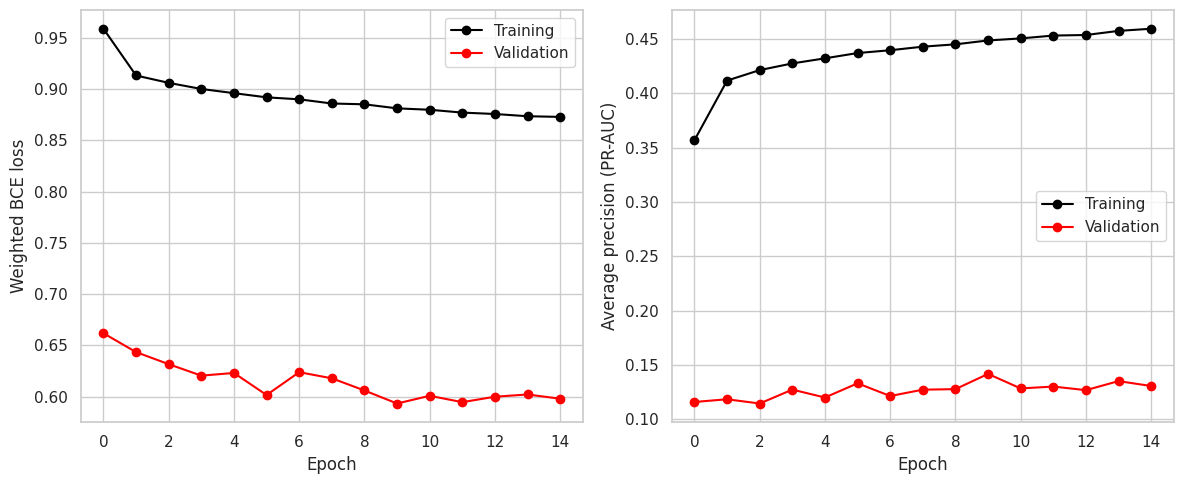

In [ ]:
def plot_history(logger, col, ylabel, ax):
    results = pd.read_csv(logger.experiment.metrics_file_path)
    train_col = f'train_{col}_epoch' if f'train_{col}_epoch' in results else f'train_{col}'
    for column, color, label in [(train_col, 'black', 'Training'),
                                 (f'valid_{col}', 'red', 'Validation')]:
        results.dropna(subset=[column]).plot(x='epoch', y=column, label=label,
                                             marker='o', color=color, ax=ax)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    return ax

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_history(mlp_logger, 'loss', 'Weighted BCE loss', axes[0])
plot_history(mlp_logger, 'average_precision', 'Average precision (PR-AUC)', axes[1])
fig.tight_layout()

## 11. Evaluation

In [ ]:
mlp_model = load_best(mlp_model, mlp_ckpt)
mlp_train_prob = predict_proba(mlp_model, X_train)
mlp_val_prob = predict_proba(mlp_model, X_val)
mlp_test_prob = predict_proba(mlp_model, X_test)

for name, y, p in [('train', y_train, mlp_train_prob), ('val', y_val, mlp_val_prob),
                   ('test', y_test, mlp_test_prob)]:
    ap = average_precision_score(y, p)
    print(f"{name:5s}  PR-AUC {ap:.3f}   no-skill {y.mean():.3f}   "
          f"({ap / y.mean():.1f}x)   ROC-AUC {roc_auc_score(y, p):.3f}")

train  PR-AUC 0.463   no-skill 0.177   (2.6x)   ROC-AUC 0.809
val    PR-AUC 0.142   no-skill 0.056   (2.5x)   ROC-AUC 0.782
test   PR-AUC 0.128   no-skill 0.046   (2.8x)   ROC-AUC 0.789


Threshold chosen on validation years: 0.55


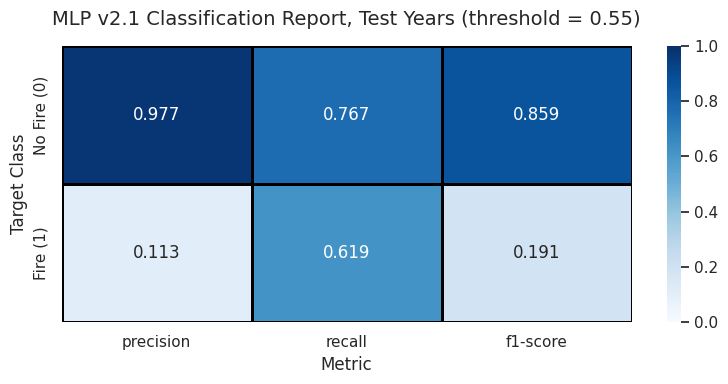

In [ ]:
# Decision threshold chosen on the VALIDATION years (best F1), then applied to test.
# (pos_weight pushes probabilities up, so 0.5 isn't meaningful here.)
candidate_thresholds = np.linspace(0.05, 0.95, 91)
val_f1 = [f1_score(y_val.astype(int), (mlp_val_prob >= t).astype(int)) for t in candidate_thresholds]
THRESHOLD = float(candidate_thresholds[int(np.argmax(val_f1))])
print(f"Threshold chosen on validation years: {THRESHOLD:.2f}")

mlp_test_pred = (mlp_test_prob >= THRESHOLD).astype(int)
report_dict = classification_report(y_test.astype(int), mlp_test_pred, zero_division=0, output_dict=True)
report_df = pd.DataFrame(
    {metric: [report_dict[cls][metric] for cls in ['0', '1']]
     for metric in ['precision', 'recall', 'f1-score']},
    index=['No Fire (0)', 'Fire (1)'],
)

plt.figure(figsize=(8, 4))
sns.set_theme(style='white')
sns.heatmap(report_df, annot=True, cmap='Blues', fmt='.3f', cbar=True,
            linewidths=1, linecolor='black', vmin=0, vmax=1)
plt.title(f'MLP v2.1 Classification Report, Test Years (threshold = {THRESHOLD:.2f})', fontsize=14, pad=15)
plt.xlabel('Metric', fontsize=12)
plt.ylabel('Target Class', fontsize=12)
plt.tight_layout()
plt.show()

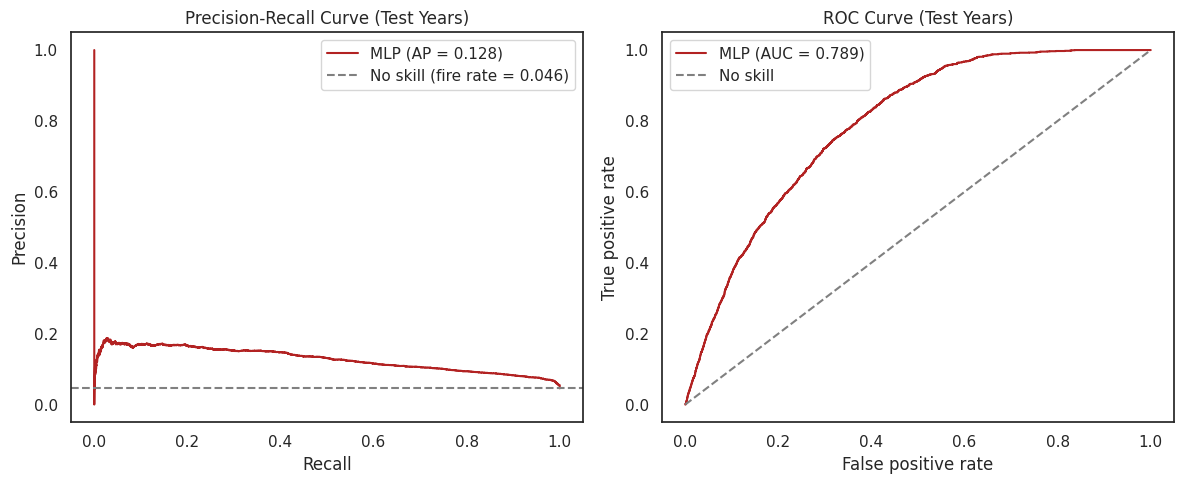

In [ ]:
precision, recall, _ = precision_recall_curve(y_test, mlp_test_prob)
fpr, tpr, _ = roc_curve(y_test, mlp_test_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.set_theme(style='whitegrid')

axes[0].plot(recall, precision, color='firebrick',
             label=f'MLP (AP = {average_precision_score(y_test, mlp_test_prob):.3f})')
axes[0].axhline(y_test.mean(), color='grey', linestyle='--',
                label=f'No skill (fire rate = {y_test.mean():.3f})')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall Curve (Test Years)')
axes[0].legend()

axes[1].plot(fpr, tpr, color='firebrick',
             label=f'MLP (AUC = {roc_auc_score(y_test, mlp_test_prob):.3f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--', label='No skill')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC Curve (Test Years)')
axes[1].legend()

plt.tight_layout()
plt.show()

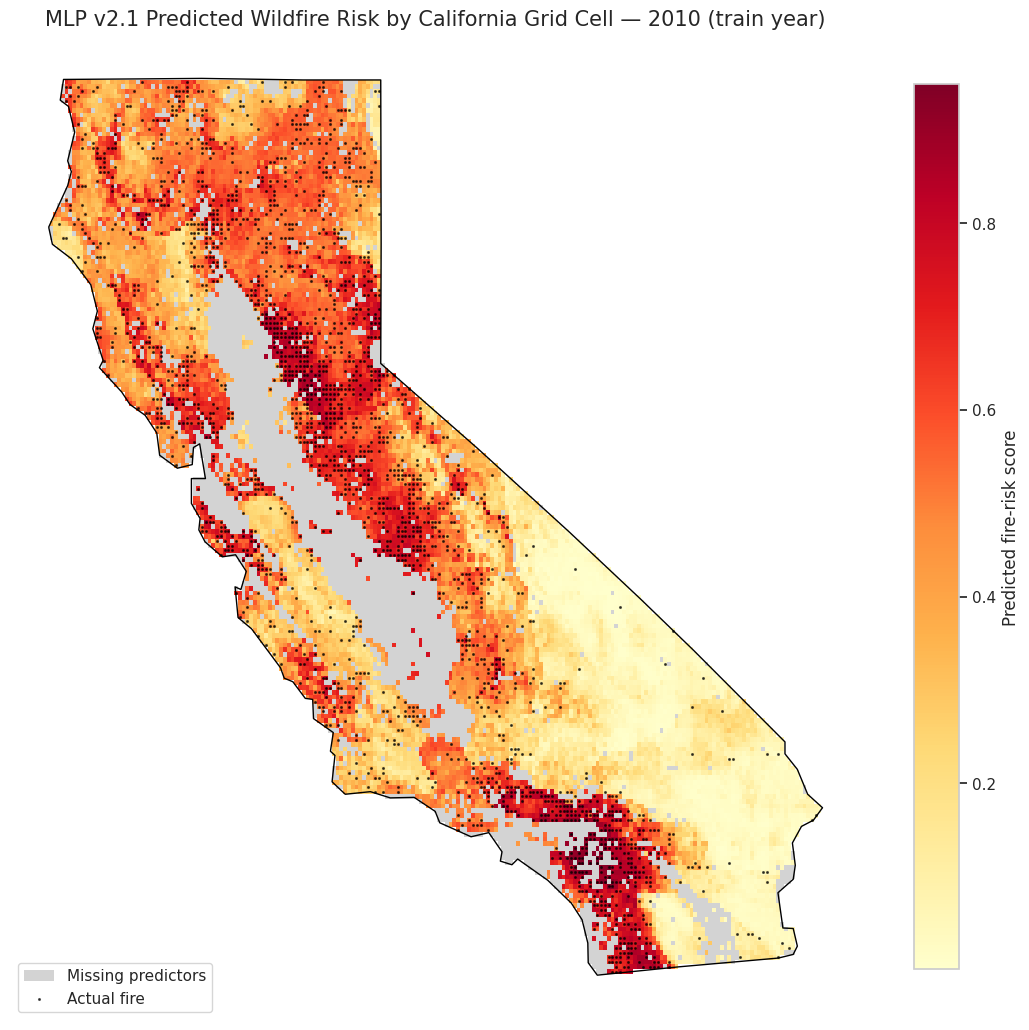

In [ ]:
X_all = preprocessor.transform(model_data[MODEL_FEATURES]).astype(np.float32)
all_predictions = model_data[['cell_id', 'year', 'split', 'fire']].copy()
all_predictions['risk_score'] = predict_proba(mlp_model, X_all)

MAP_YEAR = 2010
SHOW_ACTUAL_FIRES = True

map_data = all_predictions.loc[all_predictions['year'] == MAP_YEAR,
                               ['cell_id', 'risk_score', 'fire']]
risk_cells = california_grid[['cell_id', 'geometry']].merge(map_data, on='cell_id', how='left')
year_split = split_of_year.get(MAP_YEAR, 'unused')

fig, ax = plt.subplots(figsize=(11, 13))
risk_cells.plot(
    ax=ax,
    column='risk_score',
    cmap='YlOrRd',
    vmin=risk_cells['risk_score'].min(),
    vmax=risk_cells['risk_score'].max(),
    edgecolor='none',
    legend=True,
    legend_kwds={'label': 'Predicted fire-risk score', 'shrink': 0.7},
    missing_kwds={'color': 'lightgrey', 'label': 'Missing predictors'},
)
if SHOW_ACTUAL_FIRES:
    fire_cells = risk_cells[risk_cells['fire'] == 1]
    fire_cells.geometry.representative_point().plot(ax=ax, color='black', markersize=1.5,
                                                    alpha=0.6, label='Actual fire')
    ax.legend(loc='lower left')

california_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
ax.set_title(f'MLP v2.1 Predicted Wildfire Risk by California Grid Cell — {MAP_YEAR} '
             f'({year_split} year)', fontsize=15)
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 12. Feature importance

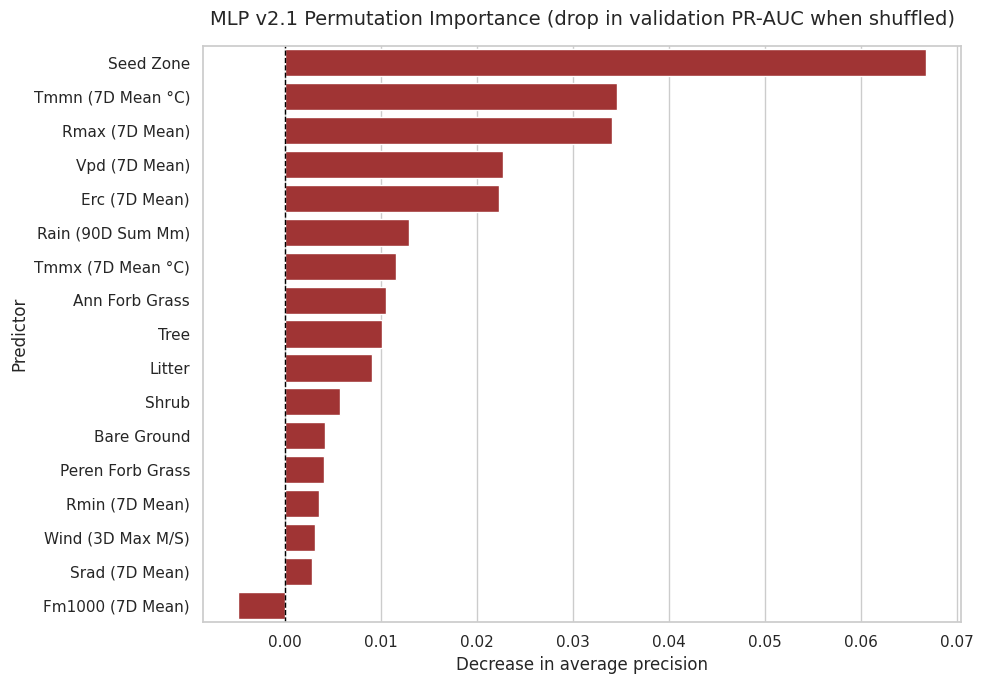

,Clean_Feature,PR-AUC drop
0,Seed Zone,0.066786
1,Tmmn (7D Mean °C),0.034577
2,Rmax (7D Mean),0.034063
3,Vpd (7D Mean),0.022709
4,Erc (7D Mean),0.022266
5,Rain (90D Sum Mm),0.012911
6,Tmmx (7D Mean °C),0.011507
7,Ann Forb Grass,0.010556
8,Tree,0.010115
9,Litter,0.009028


In [ ]:
rng = np.random.default_rng(0)
n_numeric = len(NUMERIC_FEATURES)
feature_groups = {name: [i] for i, name in enumerate(NUMERIC_FEATURES)}
feature_groups['Seed_Zone'] = list(range(n_numeric, X_val.shape[1]))   # all one-hot columns together

base_ap = average_precision_score(y_val, mlp_val_prob)
importance_rows = []
for name, cols in feature_groups.items():
    drops = []
    for _ in range(3):
        X_shuffled = X_val.copy()
        X_shuffled[:, cols] = X_val[rng.permutation(len(X_val))][:, cols]
        drops.append(base_ap - average_precision_score(y_val, predict_proba(mlp_model, X_shuffled)))
    importance_rows.append({'Feature': name, 'PR-AUC drop': np.mean(drops)})

importance = pd.DataFrame(importance_rows).sort_values('PR-AUC drop', ascending=False)
importance['Clean_Feature'] = (
    importance['Feature']
    .str.replace('_previous_7_day_mean_c', ' (7d Mean °C)')
    .str.replace('_previous_90_days_mm', ' (90d Sum mm)')
    .str.replace('_previous_3_day_max', ' (3d Max m/s)')
    .str.replace('_previous_7_day_mean', ' (7d Mean)')
    .str.replace('_', ' ')
    .str.title()
)

plt.figure(figsize=(10, 7))
sns.set_theme(style='whitegrid')
sns.barplot(data=importance, x='PR-AUC drop', y='Clean_Feature', color='firebrick')
plt.title('MLP v2.1 Permutation Importance (drop in validation PR-AUC when shuffled)', fontsize=14, pad=15)
plt.xlabel('Decrease in average precision', fontsize=12)
plt.ylabel('Predictor', fontsize=12)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

importance[['Clean_Feature', 'PR-AUC drop']].reset_index(drop=True)

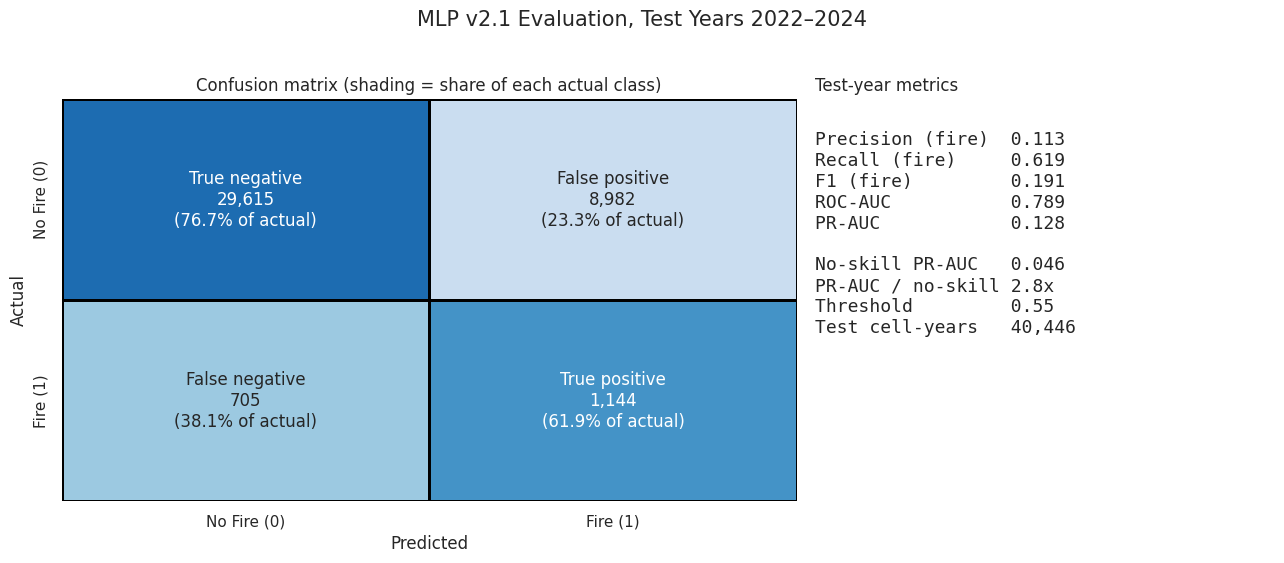

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

y_true = y_test.astype(int)
cm = confusion_matrix(y_true, mlp_test_pred, labels=[0, 1])
cm_row_pct = cm / cm.sum(axis=1, keepdims=True)      # share of each actual class

cell_names = np.array([['True negative', 'False positive'],
                       ['False negative', 'True positive']])
annot = np.array([[f"{cell_names[i, j]}\n{cm[i, j]:,}\n({cm_row_pct[i, j]:.1%} of actual)"
                   for j in range(2)] for i in range(2)])

metrics = {
    'Precision (fire)': precision_score(y_true, mlp_test_pred, zero_division=0),
    'Recall (fire)':    recall_score(y_true, mlp_test_pred, zero_division=0),
    'F1 (fire)':        f1_score(y_true, mlp_test_pred, zero_division=0),
    'ROC-AUC':          roc_auc_score(y_test, mlp_test_prob),
    'PR-AUC':           average_precision_score(y_test, mlp_test_prob),
}

fig, (ax_cm, ax_txt) = plt.subplots(1, 2, figsize=(13, 5.5),
                                    gridspec_kw={'width_ratios': [1.6, 1]})
sns.set_theme(style='white')
sns.heatmap(cm_row_pct, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
            linewidths=1, linecolor='black', annot_kws={'fontsize': 12}, ax=ax_cm,
            xticklabels=['No Fire (0)', 'Fire (1)'], yticklabels=['No Fire (0)', 'Fire (1)'])
ax_cm.set_xlabel('Predicted', fontsize=12)
ax_cm.set_ylabel('Actual', fontsize=12)
ax_cm.set_title('Confusion matrix (shading = share of each actual class)', fontsize=12)

ax_txt.axis('off')
lines = [f"{name:<18}{value:.3f}" for name, value in metrics.items()]
lines += ['',
          f"{'No-skill PR-AUC':<18}{y_test.mean():.3f}",
          f"{'PR-AUC / no-skill':<18}{metrics['PR-AUC'] / y_test.mean():.1f}x",
          f"{'Threshold':<18}{THRESHOLD:.2f}",
          f"{'Test cell-years':<18}{len(y_true):,}"]
ax_txt.text(0.0, 0.92, '\n'.join(lines), va='top', family='monospace', fontsize=13)
ax_txt.set_title('Test-year metrics', fontsize=12, loc='left')

fig.suptitle(f'MLP v2.1 Evaluation, Test Years {min(TEST_YEARS)}–{max(TEST_YEARS)}',
             fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## MLP v2.2: Changing `pos_weight` value - same architecture

In [ ]:
model_data = full_data.dropna(subset=MODEL_FEATURES).copy()
model_data['Seed_Zone'] = model_data['Seed_Zone'].astype(str)

split_of_year = {**{y: 'train' for y in TRAIN_YEARS},
                 **{y: 'val' for y in VAL_YEARS},
                 **{y: 'test' for y in TEST_YEARS}}
model_data['split'] = model_data['year'].map(split_of_year)
parts = {name: model_data[model_data['split'] == name] for name in ['train', 'val', 'test']}

preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), NUMERIC_FEATURES),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
])
preprocessor.fit(parts['train'][MODEL_FEATURES])
feature_names = list(preprocessor.get_feature_names_out())

META_COLS = ['cell_id', 'year', 'grid_lat', 'grid_lon']


def make_arrays(df):
    X = preprocessor.transform(df[MODEL_FEATURES]).astype(np.float32)
    y = df['fire'].to_numpy(dtype=np.float32)
    meta = df[META_COLS].reset_index(drop=True)
    return X, y, meta


X_train, y_train, meta_train = make_arrays(parts['train'])
X_val,   y_val,   meta_val   = make_arrays(parts['val'])
X_test,  y_test,  meta_test  = make_arrays(parts['test'])

pos_weight = 2 * (float((y_train == 0).sum() / max((y_train == 1).sum(), 1)))

print(f"{len(feature_names)} input features "
      f"({len(NUMERIC_FEATURES)} numeric + {len(feature_names) - len(NUMERIC_FEATURES)} seed-zone columns)")
for name, X, y in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    print(f"{name:5s}  X {X.shape}   fire rate {y.mean():.3%}")
print(f"pos_weight = {pos_weight:.1f}")


import torch
from torch import nn
from torch.utils.data import TensorDataset
from torchinfo import summary
from torchmetrics.classification import BinaryAveragePrecision, BinaryAUROC

from pytorch_lightning import Trainer, seed_everything
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

from ISLP.torch import SimpleDataModule, SimpleModule, ErrorTracker, rec_num_workers
from sklearn.metrics import (average_precision_score, roc_auc_score, classification_report,
                             precision_recall_curve, roc_curve, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns

seed_everything(0, workers=True)
torch.use_deterministic_algorithms(True, warn_only=True)
max_num_workers = rec_num_workers()



INFO:lightning_fabric.utilities.seed:Seed set to 0


102 input features (16 numeric + 86 seed-zone columns)
train  X (256158, 102)   fire rate 17.697%
val    X (40446, 102)   fire rate 5.650%
test   X (40446, 102)   fire rate 4.572%
pos_weight = 9.3


In [ ]:
def to_dataset(X, y):
    return TensorDataset(torch.from_numpy(X), torch.from_numpy(y))

train_ds = to_dataset(X_train, y_train)
val_ds   = to_dataset(X_val, y_val)
test_ds  = to_dataset(X_test, y_test)

fire_dm = SimpleDataModule(train_ds,
                           test_ds,
                           validation=val_ds,      # 2019-2021, not a random split
                           num_workers=max_num_workers,
                           batch_size=1024)

for idx, (X_, Y_) in enumerate(fire_dm.train_dataloader()):
    print('X: ', X_.shape, X_.dtype)
    print('Y: ', Y_.shape, Y_.dtype)
    if idx >= 1:
        break



class WildfireMLP(nn.Module):
    def __init__(self, n_inputs, hidden=(128, 64), dropout=0.3):
        super().__init__()
        layers = []
        prev = n_inputs
        for units in hidden:                      # each hidden layer: Linear -> ReLU -> Dropout
            layers += [nn.Linear(prev, units), nn.ReLU(), nn.Dropout(dropout)]
            prev = units
        layers.append(nn.Linear(prev, 1))         # one output: the log-odds of fire
        self._forward = nn.Sequential(*layers)

    def forward(self, x):
        return self._forward(x).squeeze(-1)       # shape (batch,) to match y

n_inputs = X_train.shape[1]
mlp_model = WildfireMLP(n_inputs)
print(mlp_model(X_).shape)
summary(mlp_model, input_data=X_, col_names=['input_size', 'output_size', 'num_params'])


def make_module(model, lr=1e-3):
    return SimpleModule(
        model,
        loss=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight)),  # class weighting
        optimizer=torch.optim.Adam(model.parameters(), lr=lr),
        metrics={'average_precision': BinaryAveragePrecision(),
                 'auroc': BinaryAUROC()},
        pre_process_y_for_metrics=lambda y: y.int(),
    )


def fit_model(model, name, max_epochs=30, patience=5, lr=1e-3):
    module = make_module(model, lr=lr)
    logger = CSVLogger('logs', name=name)
    checkpoint = ModelCheckpoint(monitor='valid_average_precision', mode='max')
    trainer = Trainer(deterministic=True,
                      accelerator='cpu',
                      max_epochs=max_epochs,
                      logger=logger,
                      enable_progress_bar=False,
                      callbacks=[ErrorTracker(),
                                 EarlyStopping(monitor='valid_average_precision',
                                               mode='max', patience=patience),
                                 checkpoint])
    trainer.fit(module, datamodule=fire_dm)
    return trainer, module, logger, checkpoint


def load_best(model, checkpoint):
    state = torch.load(checkpoint.best_model_path, map_location='cpu', weights_only=False)['state_dict']
    model.load_state_dict({k.removeprefix('model.'): v
                           for k, v in state.items() if k.startswith('model.')})
    return model


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X))).numpy()

X:  torch.Size([1024, 102]) torch.float32
Y:  torch.Size([1024]) torch.float32
X:  torch.Size([1024, 102]) torch.float32
Y:  torch.Size([1024]) torch.float32
torch.Size([1024])


In [ ]:
mlp_trainer, mlp_module, mlp_logger, mlp_ckpt = fit_model(mlp_model, 'Wildfire_MLP_v2.2')

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ WildfireMLP       │ 21.5 K │ train │     0 │
│ 1 │ loss  │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴───────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 21.5 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.5 K                                                                                               
Total estimated model params size (MB): 0.086                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

In [ ]:
mlp_model = load_best(mlp_model, mlp_ckpt)
mlp_train_prob = predict_proba(mlp_model, X_train)
mlp_val_prob = predict_proba(mlp_model, X_val)
mlp_test_prob = predict_proba(mlp_model, X_test)

for name, y, p in [('train', y_train, mlp_train_prob), ('val', y_val, mlp_val_prob),
                   ('test', y_test, mlp_test_prob)]:
    ap = average_precision_score(y, p)
    print(f"{name:5s}  PR-AUC {ap:.3f}   no-skill {y.mean():.3f}   "
          f"({ap / y.mean():.1f}x)   ROC-AUC {roc_auc_score(y, p):.3f}")

train  PR-AUC 0.460   no-skill 0.177   (2.6x)   ROC-AUC 0.810
val    PR-AUC 0.132   no-skill 0.056   (2.3x)   ROC-AUC 0.780
test   PR-AUC 0.116   no-skill 0.046   (2.5x)   ROC-AUC 0.784


Threshold chosen on validation years: 0.74


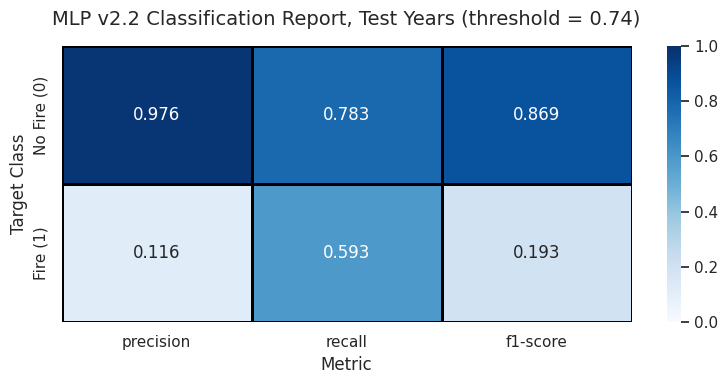

In [ ]:
# Decision threshold chosen on the VALIDATION years (best F1), then applied to test.
# (pos_weight pushes probabilities up, so 0.5 isn't meaningful here.)
candidate_thresholds = np.linspace(0.05, 0.95, 91)
val_f1 = [f1_score(y_val.astype(int), (mlp_val_prob >= t).astype(int)) for t in candidate_thresholds]
THRESHOLD = float(candidate_thresholds[int(np.argmax(val_f1))])
print(f"Threshold chosen on validation years: {THRESHOLD:.2f}")

mlp_test_pred = (mlp_test_prob >= THRESHOLD).astype(int)
report_dict = classification_report(y_test.astype(int), mlp_test_pred, zero_division=0, output_dict=True)
report_df = pd.DataFrame(
    {metric: [report_dict[cls][metric] for cls in ['0', '1']]
     for metric in ['precision', 'recall', 'f1-score']},
    index=['No Fire (0)', 'Fire (1)'],
)

plt.figure(figsize=(8, 4))
sns.set_theme(style='white')
sns.heatmap(report_df, annot=True, cmap='Blues', fmt='.3f', cbar=True,
            linewidths=1, linecolor='black', vmin=0, vmax=1)
plt.title(f'MLP v2.2 Classification Report, Test Years (threshold = {THRESHOLD:.2f})', fontsize=14, pad=15)
plt.xlabel('Metric', fontsize=12)
plt.ylabel('Target Class', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.default_rng(0)
n_numeric = len(NUMERIC_FEATURES)
feature_groups = {name: [i] for i, name in enumerate(NUMERIC_FEATURES)}
feature_groups['Seed_Zone'] = list(range(n_numeric, X_val.shape[1]))   # all one-hot columns together

base_ap = average_precision_score(y_val, mlp_val_prob)
importance_rows = []
for name, cols in feature_groups.items():
    drops = []
    for _ in range(3):
        X_shuffled = X_val.copy()
        X_shuffled[:, cols] = X_val[rng.permutation(len(X_val))][:, cols]
        drops.append(base_ap - average_precision_score(y_val, predict_proba(mlp_model, X_shuffled)))
    importance_rows.append({'Feature': name, 'PR-AUC drop': np.mean(drops)})

importance = pd.DataFrame(importance_rows).sort_values('PR-AUC drop', ascending=False)
importance['Clean_Feature'] = (
    importance['Feature']
    .str.replace('_previous_7_day_mean_c', ' (7d Mean °C)')
    .str.replace('_previous_90_days_mm', ' (90d Sum mm)')
    .str.replace('_previous_3_day_max', ' (3d Max m/s)')
    .str.replace('_previous_7_day_mean', ' (7d Mean)')
    .str.replace('_', ' ')
    .str.title()
)

plt.figure(figsize=(10, 7))
sns.set_theme(style='whitegrid')
sns.barplot(data=importance, x='PR-AUC drop', y='Clean_Feature', color='firebrick')
plt.title('MLP v2.1 Permutation Importance (drop in validation PR-AUC when shuffled)', fontsize=14, pad=15)
plt.xlabel('Decrease in average precision', fontsize=12)
plt.ylabel('Predictor', fontsize=12)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

importance[['Clean_Feature', 'PR-AUC drop']].reset_index(drop=True)

NameError: name 'np' is not defined

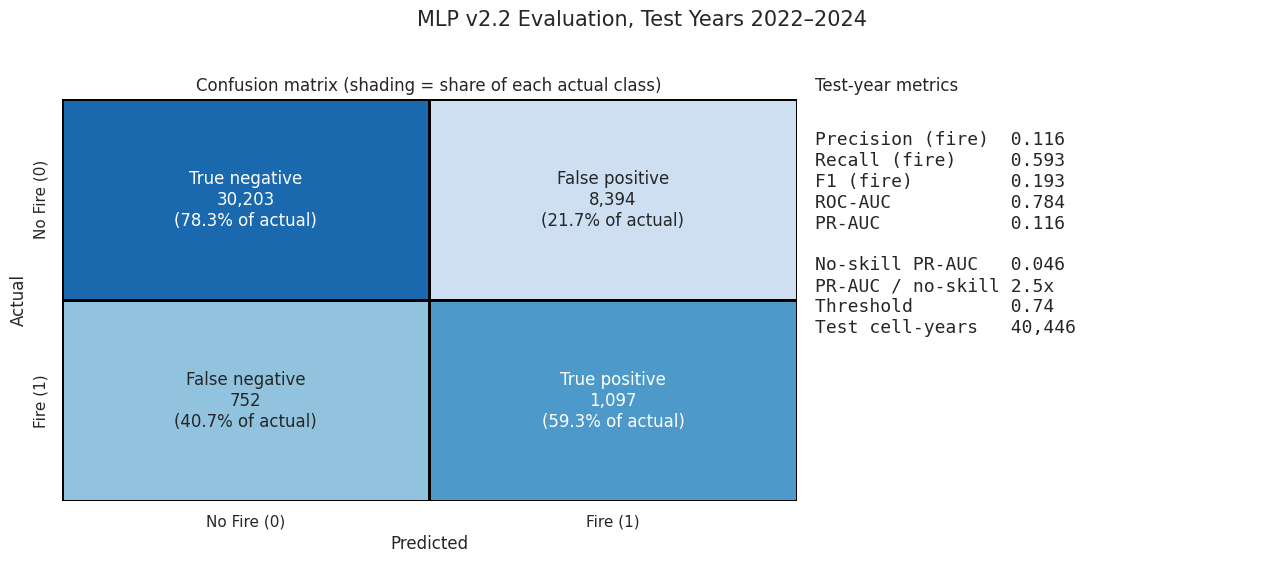

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

y_true = y_test.astype(int)
cm = confusion_matrix(y_true, mlp_test_pred, labels=[0, 1])
cm_row_pct = cm / cm.sum(axis=1, keepdims=True)      # share of each actual class

cell_names = np.array([['True negative', 'False positive'],
                       ['False negative', 'True positive']])
annot = np.array([[f"{cell_names[i, j]}\n{cm[i, j]:,}\n({cm_row_pct[i, j]:.1%} of actual)"
                   for j in range(2)] for i in range(2)])

metrics = {
    'Precision (fire)': precision_score(y_true, mlp_test_pred, zero_division=0),
    'Recall (fire)':    recall_score(y_true, mlp_test_pred, zero_division=0),
    'F1 (fire)':        f1_score(y_true, mlp_test_pred, zero_division=0),
    'ROC-AUC':          roc_auc_score(y_test, mlp_test_prob),
    'PR-AUC':           average_precision_score(y_test, mlp_test_prob),
}

fig, (ax_cm, ax_txt) = plt.subplots(1, 2, figsize=(13, 5.5),
                                    gridspec_kw={'width_ratios': [1.6, 1]})
sns.set_theme(style='white')
sns.heatmap(cm_row_pct, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
            linewidths=1, linecolor='black', annot_kws={'fontsize': 12}, ax=ax_cm,
            xticklabels=['No Fire (0)', 'Fire (1)'], yticklabels=['No Fire (0)', 'Fire (1)'])
ax_cm.set_xlabel('Predicted', fontsize=12)
ax_cm.set_ylabel('Actual', fontsize=12)
ax_cm.set_title('Confusion matrix (shading = share of each actual class)', fontsize=12)

ax_txt.axis('off')
lines = [f"{name:<18}{value:.3f}" for name, value in metrics.items()]
lines += ['',
          f"{'No-skill PR-AUC':<18}{y_test.mean():.3f}",
          f"{'PR-AUC / no-skill':<18}{metrics['PR-AUC'] / y_test.mean():.1f}x",
          f"{'Threshold':<18}{THRESHOLD:.2f}",
          f"{'Test cell-years':<18}{len(y_true):,}"]
ax_txt.text(0.0, 0.92, '\n'.join(lines), va='top', family='monospace', fontsize=13)
ax_txt.set_title('Test-year metrics', fontsize=12, loc='left')

fig.suptitle(f'MLP v2.2 Evaluation, Test Years {min(TEST_YEARS)}–{max(TEST_YEARS)}',
             fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## v2.3 - sqrt(pos_weight)

In [ ]:
model_data = full_data.dropna(subset=MODEL_FEATURES).copy()
model_data['Seed_Zone'] = model_data['Seed_Zone'].astype(str)

split_of_year = {**{y: 'train' for y in TRAIN_YEARS},
                 **{y: 'val' for y in VAL_YEARS},
                 **{y: 'test' for y in TEST_YEARS}}
model_data['split'] = model_data['year'].map(split_of_year)
parts = {name: model_data[model_data['split'] == name] for name in ['train', 'val', 'test']}

preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), NUMERIC_FEATURES),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
])
preprocessor.fit(parts['train'][MODEL_FEATURES])
feature_names = list(preprocessor.get_feature_names_out())

META_COLS = ['cell_id', 'year', 'grid_lat', 'grid_lon']


def make_arrays(df):
    X = preprocessor.transform(df[MODEL_FEATURES]).astype(np.float32)
    y = df['fire'].to_numpy(dtype=np.float32)
    meta = df[META_COLS].reset_index(drop=True)
    return X, y, meta


X_train, y_train, meta_train = make_arrays(parts['train'])
X_val,   y_val,   meta_val   = make_arrays(parts['val'])
X_test,  y_test,  meta_test  = make_arrays(parts['test'])

pos_weight = np.sqrt(float((y_train == 0).sum() / max((y_train == 1).sum(), 1)))

print(f"{len(feature_names)} input features "
      f"({len(NUMERIC_FEATURES)} numeric + {len(feature_names) - len(NUMERIC_FEATURES)} seed-zone columns)")
for name, X, y in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    print(f"{name:5s}  X {X.shape}   fire rate {y.mean():.3%}")
print(f"pos_weight = {pos_weight:.1f}")


import torch
from torch import nn
from torch.utils.data import TensorDataset
from torchinfo import summary
from torchmetrics.classification import BinaryAveragePrecision, BinaryAUROC

from pytorch_lightning import Trainer, seed_everything
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

from ISLP.torch import SimpleDataModule, SimpleModule, ErrorTracker, rec_num_workers
from sklearn.metrics import (average_precision_score, roc_auc_score, classification_report,
                             precision_recall_curve, roc_curve, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

seed_everything(0, workers=True)
torch.use_deterministic_algorithms(True, warn_only=True)
max_num_workers = rec_num_workers()

def to_dataset(X, y):
    return TensorDataset(torch.from_numpy(X), torch.from_numpy(y))

train_ds = to_dataset(X_train, y_train)
val_ds   = to_dataset(X_val, y_val)
test_ds  = to_dataset(X_test, y_test)

fire_dm = SimpleDataModule(train_ds,
                           test_ds,
                           validation=val_ds,      # 2019-2021, not a random split
                           num_workers=max_num_workers,
                           batch_size=1024)

for idx, (X_, Y_) in enumerate(fire_dm.train_dataloader()):
    print('X: ', X_.shape, X_.dtype)
    print('Y: ', Y_.shape, Y_.dtype)
    if idx >= 1:
        break



class WildfireMLP(nn.Module):
    def __init__(self, n_inputs, hidden=(128, 64), dropout=0.3):
        super().__init__()
        layers = []
        prev = n_inputs
        for units in hidden:                      # each hidden layer: Linear -> ReLU -> Dropout
            layers += [nn.Linear(prev, units), nn.ReLU(), nn.Dropout(dropout)]
            prev = units
        layers.append(nn.Linear(prev, 1))         # one output: the log-odds of fire
        self._forward = nn.Sequential(*layers)

    def forward(self, x):
        return self._forward(x).squeeze(-1)       # shape (batch,) to match y

n_inputs = X_train.shape[1]
mlp_model = WildfireMLP(n_inputs)
print(mlp_model(X_).shape)
summary(mlp_model, input_data=X_, col_names=['input_size', 'output_size', 'num_params'])


def make_module(model, lr=1e-3):
    return SimpleModule(
        model,
        loss=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight)),  # class weighting
        optimizer=torch.optim.Adam(model.parameters(), lr=lr),
        metrics={'average_precision': BinaryAveragePrecision(),
                 'auroc': BinaryAUROC()},
        pre_process_y_for_metrics=lambda y: y.int(),
    )


def fit_model(model, name, max_epochs=30, patience=5, lr=1e-3):
    module = make_module(model, lr=lr)
    logger = CSVLogger('logs', name=name)
    checkpoint = ModelCheckpoint(monitor='valid_average_precision', mode='max')
    trainer = Trainer(deterministic=True,
                      accelerator='cpu',
                      max_epochs=max_epochs,
                      logger=logger,
                      enable_progress_bar=False,
                      callbacks=[ErrorTracker(),
                                 EarlyStopping(monitor='valid_average_precision',
                                               mode='max', patience=patience),
                                 checkpoint])
    trainer.fit(module, datamodule=fire_dm)
    return trainer, module, logger, checkpoint


def load_best(model, checkpoint):
    state = torch.load(checkpoint.best_model_path, map_location='cpu', weights_only=False)['state_dict']
    model.load_state_dict({k.removeprefix('model.'): v
                           for k, v in state.items() if k.startswith('model.')})
    return model


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X))).numpy()

INFO:lightning_fabric.utilities.seed:Seed set to 0


102 input features (16 numeric + 86 seed-zone columns)
train  X (256158, 102)   fire rate 17.697%
val    X (40446, 102)   fire rate 5.650%
test   X (40446, 102)   fire rate 4.572%
pos_weight = 2.2
X:  torch.Size([1024, 102]) torch.float32
Y:  torch.Size([1024]) torch.float32
X:  torch.Size([1024, 102]) torch.float32
Y:  torch.Size([1024]) torch.float32
torch.Size([1024])


In [ ]:
mlp_trainer, mlp_module, mlp_logger, mlp_ckpt = fit_model(mlp_model, 'Wildfire_MLP_v2.3')

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ WildfireMLP       │ 21.5 K │ train │     0 │
│ 1 │ loss  │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴───────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 21.5 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.5 K                                                                                               
Total estimated model params size (MB): 0.086                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

In [ ]:
mlp_model = load_best(mlp_model, mlp_ckpt)
mlp_train_prob = predict_proba(mlp_model, X_train)
mlp_val_prob = predict_proba(mlp_model, X_val)
mlp_test_prob = predict_proba(mlp_model, X_test)

for name, y, p in [('train', y_train, mlp_train_prob), ('val', y_val, mlp_val_prob),
                   ('test', y_test, mlp_test_prob)]:
    ap = average_precision_score(y, p)
    print(f"{name:5s}  PR-AUC {ap:.3f}   no-skill {y.mean():.3f}   "
          f"({ap / y.mean():.1f}x)   ROC-AUC {roc_auc_score(y, p):.3f}")

train  PR-AUC 0.472   no-skill 0.177   (2.7x)   ROC-AUC 0.809
val    PR-AUC 0.146   no-skill 0.056   (2.6x)   ROC-AUC 0.786
test   PR-AUC 0.130   no-skill 0.046   (2.8x)   ROC-AUC 0.791


Threshold chosen on validation years: 0.38


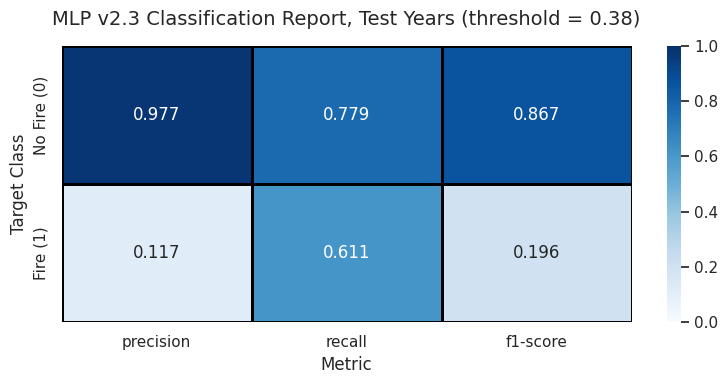

In [ ]:
# Decision threshold chosen on the VALIDATION years (best F1), then applied to test.
# (pos_weight pushes probabilities up, so 0.5 isn't meaningful here.)
candidate_thresholds = np.linspace(0.05, 0.95, 91)
val_f1 = [f1_score(y_val.astype(int), (mlp_val_prob >= t).astype(int)) for t in candidate_thresholds]
THRESHOLD = float(candidate_thresholds[int(np.argmax(val_f1))])
print(f"Threshold chosen on validation years: {THRESHOLD:.2f}")

mlp_test_pred = (mlp_test_prob >= THRESHOLD).astype(int)
report_dict = classification_report(y_test.astype(int), mlp_test_pred, zero_division=0, output_dict=True)
report_df = pd.DataFrame(
    {metric: [report_dict[cls][metric] for cls in ['0', '1']]
     for metric in ['precision', 'recall', 'f1-score']},
    index=['No Fire (0)', 'Fire (1)'],
)

plt.figure(figsize=(8, 4))
sns.set_theme(style='white')
sns.heatmap(report_df, annot=True, cmap='Blues', fmt='.3f', cbar=True,
            linewidths=1, linecolor='black', vmin=0, vmax=1)
plt.title(f'MLP v2.3 Classification Report, Test Years (threshold = {THRESHOLD:.2f})', fontsize=14, pad=15)
plt.xlabel('Metric', fontsize=12)
plt.ylabel('Target Class', fontsize=12)
plt.tight_layout()
plt.show()

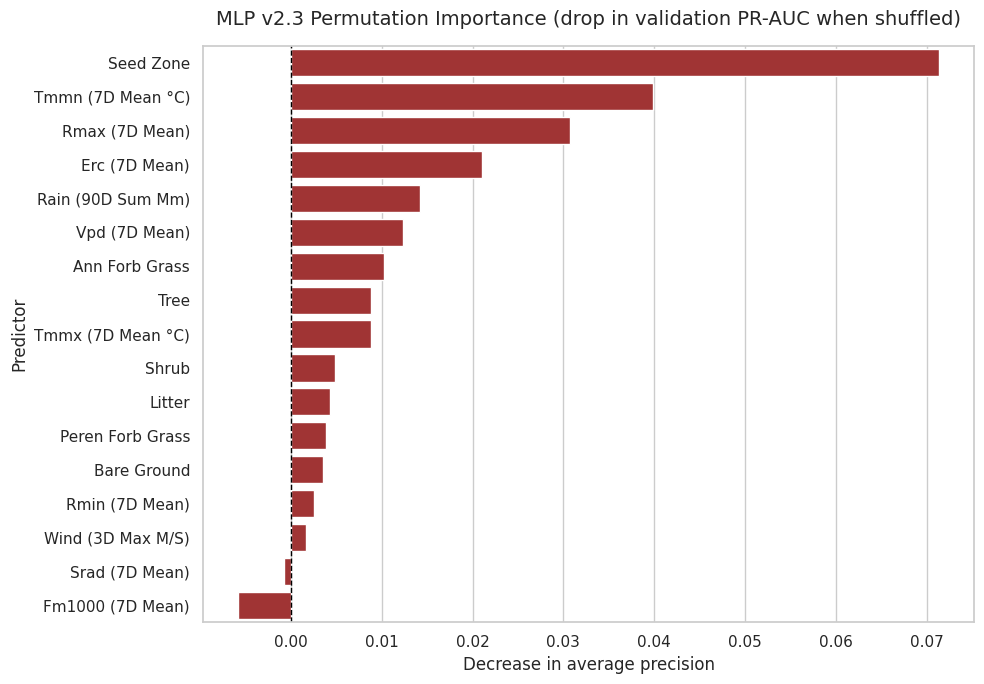

,Clean_Feature,PR-AUC drop
0,Seed Zone,0.071367
1,Tmmn (7D Mean °C),0.039901
2,Rmax (7D Mean),0.030703
3,Erc (7D Mean),0.021073
4,Rain (90D Sum Mm),0.014208
5,Vpd (7D Mean),0.012300
6,Ann Forb Grass,0.010271
7,Tree,0.008807
8,Tmmx (7D Mean °C),0.008806
9,Shrub,0.004864


In [ ]:
rng = np.random.default_rng(0)
n_numeric = len(NUMERIC_FEATURES)
feature_groups = {name: [i] for i, name in enumerate(NUMERIC_FEATURES)}
feature_groups['Seed_Zone'] = list(range(n_numeric, X_val.shape[1]))   # all one-hot columns together

base_ap = average_precision_score(y_val, mlp_val_prob)
importance_rows = []
for name, cols in feature_groups.items():
    drops = []
    for _ in range(3):
        X_shuffled = X_val.copy()
        X_shuffled[:, cols] = X_val[rng.permutation(len(X_val))][:, cols]
        drops.append(base_ap - average_precision_score(y_val, predict_proba(mlp_model, X_shuffled)))
    importance_rows.append({'Feature': name, 'PR-AUC drop': np.mean(drops)})

importance = pd.DataFrame(importance_rows).sort_values('PR-AUC drop', ascending=False)
importance['Clean_Feature'] = (
    importance['Feature']
    .str.replace('_previous_7_day_mean_c', ' (7d Mean °C)')
    .str.replace('_previous_90_days_mm', ' (90d Sum mm)')
    .str.replace('_previous_3_day_max', ' (3d Max m/s)')
    .str.replace('_previous_7_day_mean', ' (7d Mean)')
    .str.replace('_', ' ')
    .str.title()
)

plt.figure(figsize=(10, 7))
sns.set_theme(style='whitegrid')
sns.barplot(data=importance, x='PR-AUC drop', y='Clean_Feature', color='firebrick')
plt.title('MLP v2.3 Permutation Importance (drop in validation PR-AUC when shuffled)', fontsize=14, pad=15)
plt.xlabel('Decrease in average precision', fontsize=12)
plt.ylabel('Predictor', fontsize=12)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

importance[['Clean_Feature', 'PR-AUC drop']].reset_index(drop=True)

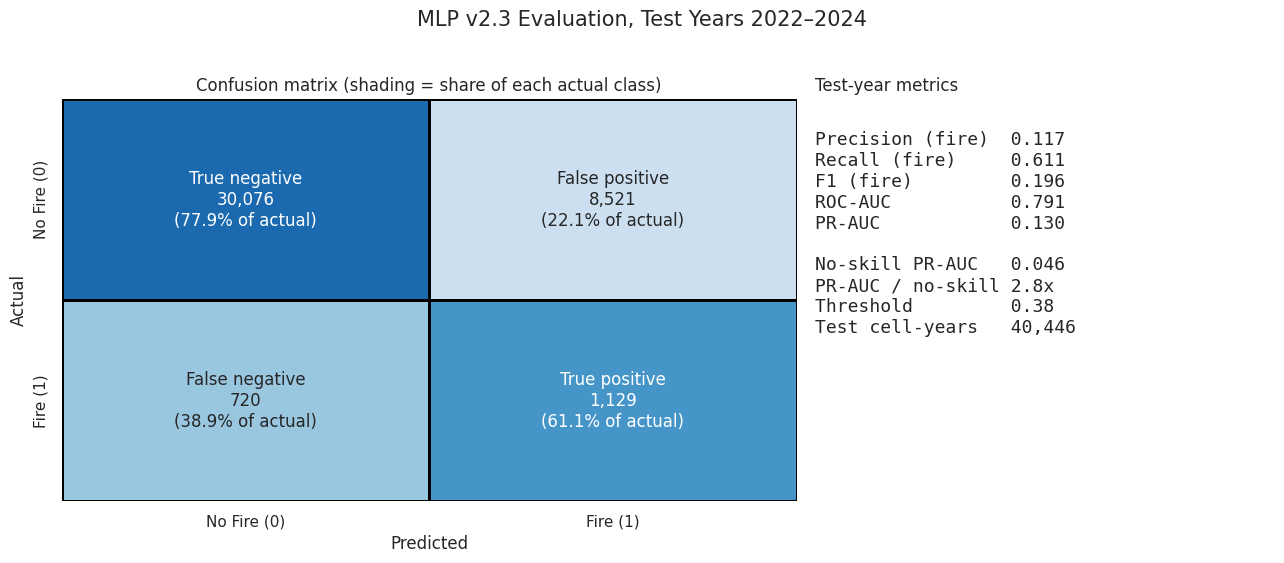

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

y_true = y_test.astype(int)
cm = confusion_matrix(y_true, mlp_test_pred, labels=[0, 1])
cm_row_pct = cm / cm.sum(axis=1, keepdims=True)      # share of each actual class

cell_names = np.array([['True negative', 'False positive'],
                       ['False negative', 'True positive']])
annot = np.array([[f"{cell_names[i, j]}\n{cm[i, j]:,}\n({cm_row_pct[i, j]:.1%} of actual)"
                   for j in range(2)] for i in range(2)])

metrics = {
    'Precision (fire)': precision_score(y_true, mlp_test_pred, zero_division=0),
    'Recall (fire)':    recall_score(y_true, mlp_test_pred, zero_division=0),
    'F1 (fire)':        f1_score(y_true, mlp_test_pred, zero_division=0),
    'ROC-AUC':          roc_auc_score(y_test, mlp_test_prob),
    'PR-AUC':           average_precision_score(y_test, mlp_test_prob),
}

fig, (ax_cm, ax_txt) = plt.subplots(1, 2, figsize=(13, 5.5),
                                    gridspec_kw={'width_ratios': [1.6, 1]})
sns.set_theme(style='white')
sns.heatmap(cm_row_pct, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
            linewidths=1, linecolor='black', annot_kws={'fontsize': 12}, ax=ax_cm,
            xticklabels=['No Fire (0)', 'Fire (1)'], yticklabels=['No Fire (0)', 'Fire (1)'])
ax_cm.set_xlabel('Predicted', fontsize=12)
ax_cm.set_ylabel('Actual', fontsize=12)
ax_cm.set_title('Confusion matrix (shading = share of each actual class)', fontsize=12)

ax_txt.axis('off')
lines = [f"{name:<18}{value:.3f}" for name, value in metrics.items()]
lines += ['',
          f"{'No-skill PR-AUC':<18}{y_test.mean():.3f}",
          f"{'PR-AUC / no-skill':<18}{metrics['PR-AUC'] / y_test.mean():.1f}x",
          f"{'Threshold':<18}{THRESHOLD:.2f}",
          f"{'Test cell-years':<18}{len(y_true):,}"]
ax_txt.text(0.0, 0.92, '\n'.join(lines), va='top', family='monospace', fontsize=13)
ax_txt.set_title('Test-year metrics', fontsize=12, loc='left')

fig.suptitle(f'MLP v2.3 Evaluation, Test Years {min(TEST_YEARS)}–{max(TEST_YEARS)}',
             fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# MLP model comparison

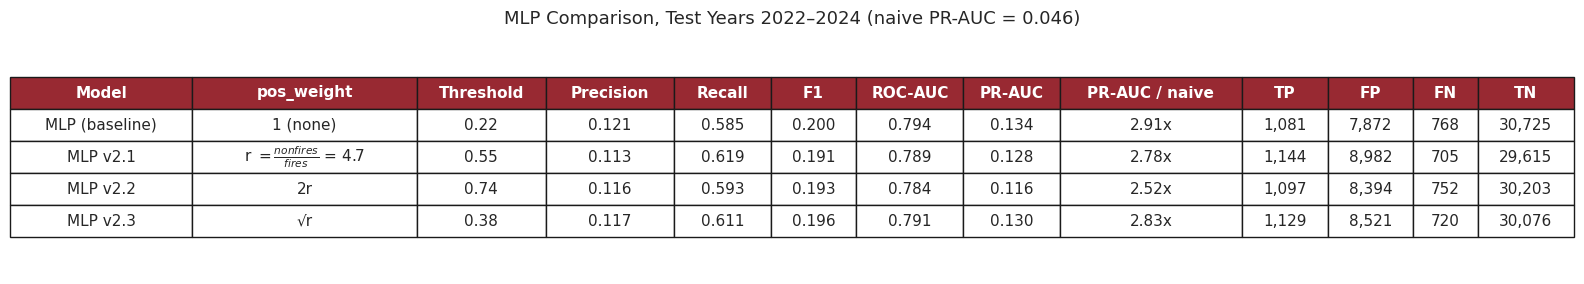

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Test-year results (2022-2024) for each MLP run, taken from the evaluation figures.
# r = class ratio (non-fire rows / fire rows in the training years); 1 = no class weighting
results = pd.DataFrame([
    {'Model': 'MLP (baseline)', 'pos_weight': '1 (none)', 'Threshold': 0.22,
     'Precision': 0.121, 'Recall': 0.585, 'F1': 0.200, 'ROC-AUC': 0.794, 'PR-AUC': 0.134,
     'TP': 1081, 'FP': 7872, 'FN': 768, 'TN': 30725},
    {'Model': 'MLP v2.1', 'pos_weight': r'r $= \frac{nonfires}{fires}$ = 4.7',  'Threshold': 0.55,
     'Precision': 0.113, 'Recall': 0.619, 'F1': 0.191, 'ROC-AUC': 0.789, 'PR-AUC': 0.128,
     'TP': 1144, 'FP': 8982, 'FN': 705, 'TN': 29615},
    {'Model': 'MLP v2.2', 'pos_weight': '2r', 'Threshold': 0.74,
     'Precision': 0.116, 'Recall': 0.593, 'F1': 0.193, 'ROC-AUC': 0.784, 'PR-AUC': 0.116,
     'TP': 1097, 'FP': 8394, 'FN': 752, 'TN': 30203},
    {'Model': 'MLP v2.3', 'pos_weight': '√r', 'Threshold': 0.38,
     'Precision': 0.117, 'Recall': 0.611, 'F1': 0.196, 'ROC-AUC': 0.791, 'PR-AUC': 0.130,
     'TP': 1129, 'FP': 8521, 'FN': 720, 'TN': 30076},
])
NAIVE_PR_AUC = 0.046   # test-year fire rate (PR-AUC of a random ranking)
results['PR-AUC / naive'] = results['PR-AUC'] / NAIVE_PR_AUC
results = results[['Model', 'pos_weight', 'Threshold', 'Precision', 'Recall', 'F1', 'ROC-AUC',
                   'PR-AUC', 'PR-AUC / naive', 'TP', 'FP', 'FN', 'TN']]

# Format the numbers for display
display_df = results.copy()
for col in ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    display_df[col] = display_df[col].map('{:.3f}'.format)
display_df['Threshold'] = display_df['Threshold'].map('{:.2f}'.format)
display_df['PR-AUC / naive'] = display_df['PR-AUC / naive'].map('{:.2f}x'.format)
for col in ['TP', 'FP', 'FN', 'TN']:
    display_df[col] = display_df[col].map('{:,}'.format)

fig, ax = plt.subplots(figsize=(16, 3.0))
ax.axis('off')
# Column widths sized to the longest entry in each column, plus padding
char_len = [min(max(len(str(c)), display_df[c].astype(str).str.len().max()), 18)
            for c in display_df.columns]
col_widths = [(n + 3) / sum(n + 3 for n in char_len) for n in char_len]
table = ax.table(cellText=display_df.values, colLabels=display_df.columns,
                 colWidths=col_widths, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.9)

# Header styling
for j in range(len(display_df.columns)):
    cell = table[0, j]
    cell.set_facecolor('#982932')
    cell.set_text_props(color='white', weight='bold')

ax.set_title('MLP Comparison, Test Years 2022–2024 '
             f'(naive PR-AUC = {NAIVE_PR_AUC:.3f})',
             fontsize=13, pad=12)
plt.tight_layout()
plt.show()

## Results: MLP comparison (test years 2022–2024)

### Setup
All four models share the same design: a feed-forward network with two hidden layers (128 and 64 units, ReLU, 30% dropout). Each row is a ~5 km grid cell in one year, labeled 1 if at least one fire started there that year. The inputs are 10 gridMET fire-season weather variables, 6 RAP vegetation-cover variables, and the cell's seed zone. Models were trained on 2000–2018, tuned and early-stopped on 2019–2021, and evaluated once on 2022–2024 (40,446 cell-years, 1,849 with a fire, a fire rate of 4.6%).

The only difference between the models is how the loss treats the rare fire class. `pos_weight` multiplies the loss of every fire row:
- **Baseline:** no weighting (`pos_weight` = 1)
- **v2.1:** `pos_weight` = r = (non-fire rows ÷ fire rows in the training years) ≈ 4.7, so both classes carry equal total weight
- **v2.2:** `pos_weight` = 2r ≈ 9.4
- **v2.3:** `pos_weight` = √r ≈ 2.2

For each model, the decision threshold was set to the value that maximized F1 for the fire class on the validation years, then applied unchanged to the test years.

### How to read the metrics
- **PR-AUC** (average precision) summarizes how well the model ranks fire cells above non-fire cells, across all thresholds. A naive model that ranks cells at random scores the fire rate, 0.046. **PR-AUC / naive** shows how many times better than random each model is.
- **ROC-AUC** is the probability that a randomly chosen fire cell gets a higher score than a randomly chosen non-fire cell (0.5 = random).
- **Precision, recall, and F1** depend on the chosen threshold. Precision is the share of flagged cells that actually burned. Recall is the share of burned cells that were flagged.

### Findings
1. **All four models perform similarly and clearly beat random.** PR-AUC ranges from 0.116 to 0.134, about 2.5–2.9× the naive baseline, and ROC-AUC is about 0.79 for every model. Each catches roughly 60% of the cells that burned. Only about 1 in 8 flagged cells actually burned, which is expected for a rare, largely human-caused event predicted from weather and vegetation alone.

2. **Class weighting did not improve the model.** The unweighted baseline had the highest PR-AUC (0.134, 2.91× naive), ROC-AUC (0.794), F1 (0.200), and precision (0.121), plus the fewest false alarms. The differences between the baseline, v2.1, and v2.3 are small (PR-AUC 0.128–0.134) and likely within run-to-run variation. Doubling the weight (v2.2) was the only clearly worse setting (PR-AUC 0.116).

3. **Weighting mainly shifts the threshold, not the ranking.** A larger `pos_weight` pushes every predicted probability upward, so the threshold chosen on validation rose to match: 0.22 for the baseline, 0.38 for √r, 0.55 for r, and 0.74 for 2r. Because the threshold was re-tuned for each model, the extra weight was largely cancelled out. Tuning the threshold on held-out data handled the class imbalance as well as reweighting the loss did.

4. **The models differ mainly in the recall–precision trade-off.** v2.1 caught the most fires (recall 0.619, 705 missed), while the baseline raised the fewest false alarms (7,872 versus 8,982 for v2.1). Moving along this trade-off is better done by adjusting the threshold directly, for example choosing a threshold that reaches a target recall on the validation years, than by changing `pos_weight`.

### Conclusion
Handling the class imbalance through the loss weight (`pos_weight`) gave no benefit over an unweighted network with a validation-tuned threshold. We therefore prefer the **unweighted baseline**: it performs as well as or better than the weighted versions, and because it isn't reweighted, its predicted probabilities stay close to the true chance of fire, which makes the risk maps easier to interpret.

### Limitations
- Each model was trained once with a fixed seed, so small differences may not hold up across seeds.
- Precision is limited by the inputs: most California fires are started by people, and the model has no information on population, roads, or the wildland-urban interface.
- The annual design collapses each fire season into single extreme values, so the model can't tell whether hot, dry, and windy conditions occurred at the same time as a fire.
- The USFS labels change in what they include around 2016, so the training years (mostly pre-2016) and the test years (post-2016) don't count fires in the same way.